# $T_3$ closure test with BCDMS 

**Model:**  
$$\bm{y}= [y_1,\dots,y_n]^\top \sim \mathcal{N}\bigl(\bm{\mu}(c),\, \Sigma\bigr)$$
$$y_i = \bm{y}(x_i, Q_i^2), \quad \mu_{i}(c) = v(c;Q^2_i)\,T[f], \quad i=1,\dots,n$$

where
- $v(c;Q^2) = 1 + k_{\rm lin}(Q^2)\,c + k_{\rm quad}(Q^2)\,c^2$ encodes new-physics EFT corrections,
- $T[f]$ is the standard-model theory prediction convolved with the PDF $f$,
- $f(x)$ (or $xf(x)$) is expanded in a B-spline basis: $f(x) = \sum_k \beta_k B_k(x)$.

**Goal:** estimate $c$ while treating $f$ as an infinite-dimensional nuisance function.

**Outline**
1. Load Grid/FK Tables
2. Model Configuration
3. True PDF (from LHAPDF)
4. Theory Predictions & Data Generation
5. Fitting
   - 5a. B-spline Basis
   - 5b. Option A — Separate Fit (β first, then c)
   - 5c. Option B — Joint Fit (β and c simultaneously)
   - 5d. One-step Estimator
6. Results
7. Simulation Study
8. Uncertainty Quantification

In [39]:
import numpy as np
from scipy.integrate import fixed_quad, quad
from scipy.stats import norm
from scipy.linalg import cho_factor, cho_solve
import pandas as pd
from matplotlib import pyplot as plt
from matplotlib.lines import Line2D
from collections import defaultdict
import lhapdf

from utils import (
    # Basis
    bspline_basis,
    # Model
    klin, kquad, v_c, v_prime_c, v_second_c,
    # Design matrices & theory
    build_f_design_matrix_FK, build_yf_design_matrix_FK,
    build_K_matrix, build_K_prime_matrix,
    T_sm_FK, true_mean, true_mean_basis,
    # Fitting
    fit_beta_c, mle_beta, mle_c, one_step_c, one_step_confidence_interval, bootstrap_confidence_interval,
    joint_mle_asymptotic_confidence_interval,
    joint_mle_analytical_hessian, joint_mle_numerical_hessian,
    # Plotting
    plot_by_Q2,
    # Experiment runners
    setup_experiment, run_single_experiment,
)

---
## 1. Load Grid/FK Table

The grid/FK table is precomputed by `data_T3.py` and stored as a compressed NumPy archive.  
Key arrays:
- `W` — FK table matrix `(N_data, N_grid)`: encodes the DIS cross-section convolution
- `grid` — x-grid `(N_grid,)` that `W` integrates over
- `Sigma` — experimental covariance matrix `(N_data, N_data)`
- `kinematics` — `(N_data, 2)` array of `(x, Q²)` pairs for each data point

In [40]:
data = np.load("Dataset/data_208.npz")

Q0     = data["Q0"]         # reference scale
grid   = data["grid"]       # x-grid for FK table
W      = data["W"]          # FK table  (N_data, N_grid)
Sigma  = data["Sigma"]      # covariance (N_data, N_data)
xQ2    = data["kinematics"] # (x, Q²) pairs  (N_data, 2)
y_vals = data["y_vals"]      # y values (N_data,)
F2_d   = data["F2_d"]       # F2 values (N_data,)

print(f"N_data = {xQ2.shape[0]},  N_grid = {grid.shape[0]}")
print(f"Q² range: [{xQ2[:,1].min():.1f}, {xQ2[:,1].max():.1f}]")

N_data = 248,  N_grid = 50
Q² range: [8.8, 230.0]


In [ ]:
save_fig = False

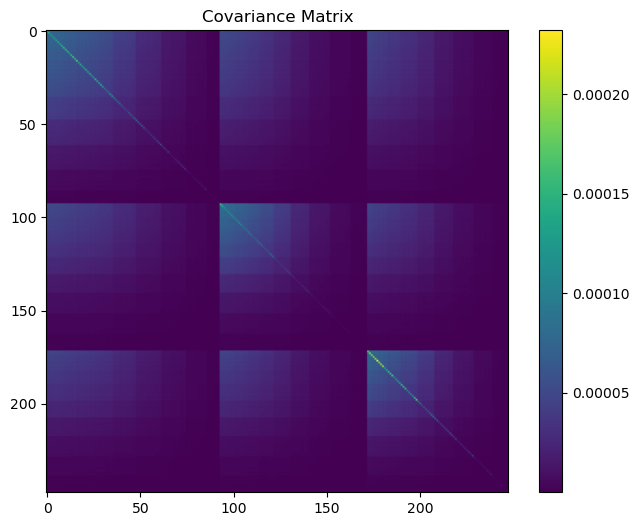

In [41]:
# visualize Sigma
plt.figure(figsize=(8, 6))
plt.imshow(Sigma, cmap='viridis')
plt.colorbar()
plt.title('Covariance Matrix')
plt.show()

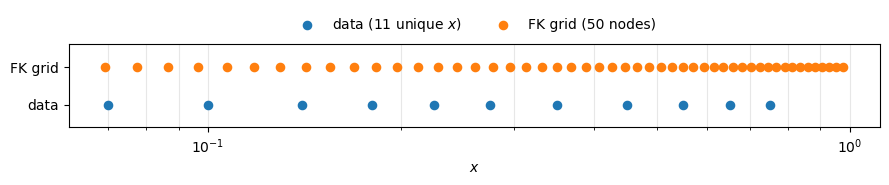

In [42]:
x_unique = np.unique(xQ2[:, 0])

fig, ax = plt.subplots(figsize=(9, 2.5))
ax.scatter(x_unique, np.zeros_like(x_unique), color="C0", s=35, zorder=3, label=f"data ({len(x_unique)} unique $x$)")
ax.scatter(grid, np.ones_like(grid), color="C1", s=35, zorder=3, label=f"FK grid ({len(grid)} nodes)")

ax.set_xscale("log")
ax.set_yticks([0, 1])
ax.set_yticklabels(["data", "FK grid"])
ax.set_ylim(-0.6, 1.6)
ax.set_xlabel("$x$")
ax.grid(True, axis="x", which="both", alpha=0.3)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, 1.5), ncols=2, frameon=False)
plt.tight_layout()
plt.show()

Plot the combined kinematic coverage of the HERA and BCDMS datasets used in the demos.

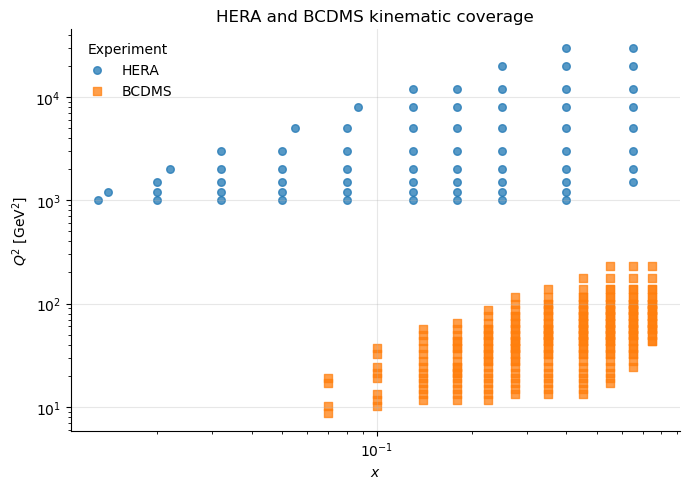

In [5]:
# Combined coverage of the HERA and BCDMS datasets used in these demos.
# This cell can run independently of the fitting and LHAPDF cells.
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

coverage_datasets = {
    "HERA": ("Dataset/data_HERA_F3_aZ_PID200.npz", "C0", "o"),
    "BCDMS": ("Dataset/data_208.npz", "C1", "s"),
}
save_coverage_fig = False
coverage_output = Path("../results/BCDMS/HERA_BCDMS_kinematic_coverage.pdf")

fig, ax = plt.subplots(figsize=(7, 5))
for experiment, (archive_path, color, marker) in coverage_datasets.items():
    with np.load(archive_path) as coverage_archive:
        coverage_points = coverage_archive["kinematics"]
    ax.scatter(
        coverage_points[:, 0], coverage_points[:, 1],
        s=30, color=color, marker=marker, alpha=0.75, label=experiment,
    )

ax.set(
    xscale="log", yscale="log", xlabel=r"$x$",
    ylabel=r"$Q^2$ [GeV$^2$]", title="HERA and BCDMS kinematic coverage",
)
ax.legend(title="Experiment", frameon=False)
ax.grid(True, which="major", alpha=0.3)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
fig.tight_layout()

if save_coverage_fig:
    coverage_output.parent.mkdir(parents=True, exist_ok=True)
    fig.savefig(coverage_output, bbox_inches="tight")
    print("Figure saved at:", coverage_output)
plt.show()


Check the singular values of `W`. The number of basis functions should not exceed the number of significant singular values to avoid overfitting.

39 / 50 grid nodes lie within the data's x-range [0.07, 0.75]
condition number (in-range nodes only): 3.25e+03


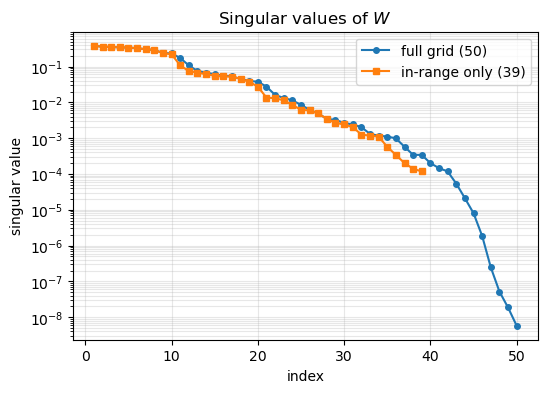

In [44]:
in_range = (grid >= x_unique.min()) & (grid <= x_unique.max())
print(f"{in_range.sum()} / {len(grid)} grid nodes lie within the data's x-range [{x_unique.min():.3g}, {x_unique.max():.3g}]")

xgrid_sub = grid[in_range]
W_sub = W[:, in_range]

sv_sub = np.linalg.svd(W_sub, compute_uv=False)
print(f"condition number (in-range nodes only): {sv_sub[0] / sv_sub[-1]:.3g}")

fig, ax = plt.subplots(figsize=(6, 4))
ax.semilogy(np.arange(1, len(singular_values) + 1), singular_values, "o-", ms=4, label=f"full grid ({len(grid)})")
ax.semilogy(np.arange(1, len(sv_sub) + 1), sv_sub, "s-", ms=4, label=f"in-range only ({len(xgrid_sub)})")
ax.set_xlabel("index")
ax.set_ylabel("singular value")
ax.set_title(r"Singular values of $W$")
ax.grid(True, which="both", alpha=0.3)
ax.legend()
plt.show()

---
## 2. Model Configuration

The EFT expansion uses two momentum-suppressed Wilson coefficients:
$$k_{\rm lin}(Q^2) = \frac{Q^2}{\Lambda^2}, \qquad k_{\rm quad}(Q^2) = \frac{Q^4}{\Lambda^4}$$

giving the polynomial factor $v(c;Q^2) = 1 + k_{\rm lin}\,c + k_{\rm quad}\,c^2$.

These are already implemented in `utils` with `Lambda=100` as the default.

In [45]:
Lambda  = 500
Q2_min  = xQ2[:, 1].min()
Q2_max  = xQ2[:, 1].max()

# Wrap klin/kquad so Lambda is fixed for this experiment
_klin  = lambda z: klin(z,  Lambda=Lambda)
#_klin = lambda z, **kwargs: np.zeros_like(np.asarray(z, dtype=float))
_kquad = lambda z: kquad(z, Lambda=Lambda)
#_kquad = lambda z, **kwargs: np.zeros_like(np.asarray(z, dtype=float))
_v_c       = lambda c, xQ2: v_c(c, xQ2, klin=_klin, kquad=_kquad)
_v_prime_c = lambda c, xQ2: v_prime_c(c, xQ2, klin=_klin, kquad=_kquad)
_v_second_c = lambda c, xQ2: v_second_c(c, xQ2, kquad=_kquad)

# Sanity check: v(c=0) should be 1 everywhere
assert np.allclose(_v_c(0, xQ2), 1.0)

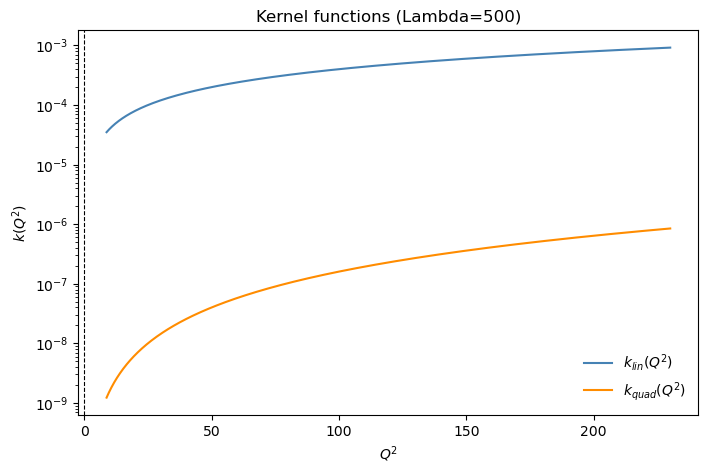

In [46]:
# Plot klin and kquad
q2_plot = np.geomspace(xQ2[:, 1].min(), xQ2[:, 1].max(), 300)
plt.figure(figsize=(8, 5))
plt.plot(q2_plot, _klin(q2_plot), label="$k_{lin}(Q^2)$", color="steelblue")
plt.plot(q2_plot, _kquad(q2_plot), label="$k_{quad}(Q^2)$", color="darkorange")
plt.axhline(0, color="black", linestyle="--", linewidth=0.8)
plt.axvline(0, color="black", linestyle="--", linewidth=0.8)
plt.xlabel("$Q^2$"); plt.ylabel("$k(Q^2)$")
plt.yscale("log")
plt.title(f"Kernel functions (Lambda={Lambda})")
plt.legend(frameon=False)

---
## 3. Reference $T_3$ and predictions

We use $T_3$ PDF from the NNPDF4.0 set as the ground-truth PDF:
$$T_3(y) = (u(y)+\bar{u}(y)) - (d(y)+\bar{d}(y)).$$

In [47]:
pdfset = "NNPDF40_nnlo_as_01180"
pdf    = lhapdf.mkPDF(pdfset, 0)

x_min = pdf.xMin
x_max = pdf.xMax
Q2_0  = Q0 ** 2

def _uv_scalar(x, Q2):
    return pdf.xfxQ2(2, x, Q2) / x + pdf.xfxQ2(-2, x, Q2) / x

def _dv_scalar(x, Q2):
    return pdf.xfxQ2(1, x, Q2) / x + pdf.xfxQ2(-1, x, Q2) / x

uv = np.vectorize(_uv_scalar, excluded={"Q2"})
dv = np.vectorize(_dv_scalar, excluded={"Q2"})

def f(x):
    return uv(x, Q2_0) - dv(x, Q2_0)

print(f"x range: [{x_min}, {x_max}]")
print("Integral of f over x range:", fixed_quad(f, x_min, x_max, n=1000)[0])

x range: [1e-09, 1.0]
LHAPDF Integral of f over x range: 0.78966468654706
6.5.5 loading /Users/richardzhs/miniforge3/envs/hep/share/LHAPDF/NNPDF40_nnlo_as_01180/NNPDF40_nnlo_as_01180_0000.dat
NNPDF40_nnlo_as_01180 PDF set, member #0, version 1; LHAPDF ID = 331100


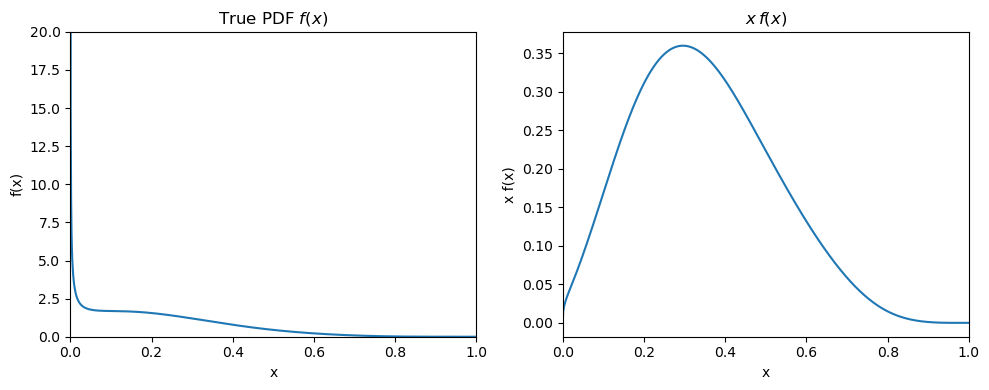

In [48]:
pt = np.linspace(x_min, x_max, 1000)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4))

ax1.plot(pt, f(pt))
ax1.set_xlim(0, 1); ax1.set_ylim(0, 20)
ax1.set_xlabel("x"); ax1.set_ylabel("f(x)"); ax1.set_title("True PDF $f(x)$")

ax2.plot(pt, pt * f(pt))
ax2.set_xlim(0, 1)
ax2.set_xlabel("x"); ax2.set_ylabel("x f(x)"); ax2.set_title("$x\,f(x)$")

plt.tight_layout(); plt.show()

---
## 4. Theory Predictions & Data Generation

The SM prediction is $T[f] = W \cdot f(\text{grid})$.  
The full mean at true $c$ is $\mu = v(c;\mathbf{Q}^2) \odot T[f]$.

In [49]:
# Standard-model theory prediction
T = T_sm_FK(f=f, W=W, grid=grid)

# True Wilson coefficient and full mean
c_true = 500
mu     = true_mean(c=c_true, T=T, xQ2=xQ2, klin=_klin, kquad=_kquad)

# Simulate one dataset
rng = np.random.default_rng(seed=0)
D   = rng.multivariate_normal(mean=mu, cov=Sigma)

---
## 5. Fitting

### 5a. B-spline Basis

Set `parametrize = "f"` to expand $f(x)$ directly, or `"xf"` to expand $xf(x)$.

**`"f"` mode:** $f(x) \approx \sum_k \beta_k B_k(x)$, normalization $\mathbf{w}^\top\boldsymbol{\beta}=1$ with $w_k = \int B_k(x)\,dx$.

**`"xf"` mode:** $xf(x) \approx \sum_k \beta_k B_k(x)$, so $f(x) = \frac{1}{x}\sum_k \beta_k B_k(x)$, normalization $w_k = \int B_k(x)/x\,dx$.

The design matrix $A \in \mathbb{R}^{N \times M}$ satisfies $T[f] \approx A\boldsymbol{\beta}$ in both cases.

In [51]:
degree      = 3    # cubic B-splines
M           = 8   # number of basis functions
parametrize = "xf"  # "f": expand f(x);  "xf": expand x*f(x)

B = bspline_basis(degree, M, x_min, x_max)

if parametrize == "f":
    w_norm = np.array([Bk.integrate(x_min, x_max) for Bk in B])
    A      = build_f_design_matrix_FK(B=B, W=W, grid=grid)
elif parametrize == "xf":
    w_norm = np.array([quad(lambda y, Bk=Bk: Bk(y) / y, x_min, x_max)[0] for Bk in B])
    A      = build_yf_design_matrix_FK(B=B, W=W, grid=grid)
else:
    raise ValueError(f"parametrize must be 'f' or 'xf', got {parametrize!r}")

print(f"Parametrize : {parametrize}")
print(f"Design matrix shape: {A.shape}  (N_data × M)")
print(f"w_norm: {w_norm.round(4)}")

Parametrize : xf
Design matrix shape: (248, 8)  (N_data × M)
w_norm: [17.2805  1.3863  0.7849  0.5573  0.3471  0.2007  0.1143  0.0521]


### 5b. Option A — Separate Fit

**Step 1:** Fix $c = c_0$ (e.g. $c_0 = 0$) and find $\hat{\boldsymbol{\beta}}$ by minimizing the NLL over $\boldsymbol{\beta}$:
$$\hat{\boldsymbol{\beta}} = \arg\min_{\boldsymbol{\beta}\ge 0} \ell(\boldsymbol{\beta},\, c_0)$$

**Step 2:** Plug $\hat{\boldsymbol{\beta}}$ in and find $\hat{c}$ by minimizing the NLL over $c$:
$$\hat{c} = \arg\min_c\; \ell(\hat{\boldsymbol{\beta}},\, c)$$

PDFs are extracted from global fits assuming the Standard Model (i.e., $c=0$), after which the fitted PDFs are used to determine the best-fit value of $c$.

In [52]:
# Step 1: fit beta with c fixed at c0=0
c0 = 0
loss_scale = 1e2

beta_hat_sep, beta_history = mle_beta(
    D=D, A=A, c=c0, v=_v_c, xQ2=xQ2,
    Sigma=Sigma, w_norm=None,
    nonneg_beta=True, pin_endpoints=True,
    beta_opt="SLSQP", return_history=True, loss_scale=loss_scale,
)

# Step 2: fit c with beta fixed
c_hat_sep = mle_c(
    D=D, A=A, v=_v_c, beta=beta_hat_sep,
    xQ2=xQ2, Sigma=Sigma,
    c_opt="L-BFGS-B", c_range=(0, 100)
)

ci_sep_lower, ci_sep_upper, cb_sep = bootstrap_confidence_interval(
    A=A, xQ2=xQ2, Sigma=Sigma, w_norm=None, c0=c0,
    c_hat=c_hat_sep, beta_hat=beta_hat_sep, c_opt="Nelder-Mead", #c_range=(0, 100),
    n_boot=500, alpha=0.05, estimator="mle", loss_scale=loss_scale,
    klin=_klin, kquad=_kquad, pin_endpoints=True,
    opt="separate", verbose=True
)

print(f"True c            = {c_true}")
print(f"Separate fit c    = {c_hat_sep:.4f}")
print(f"95% CI (separate) = [{ci_sep_lower:.4f}, {ci_sep_upper:.4f}]")

  Bootstrap replicate 50/500
  Bootstrap replicate 100/500
  Bootstrap replicate 150/500
  Bootstrap replicate 200/500
  Bootstrap replicate 250/500
  Bootstrap replicate 300/500
  Bootstrap replicate 350/500
  Bootstrap replicate 400/500
  Bootstrap replicate 450/500
  Bootstrap replicate 500/500
True c            = 500
Separate fit c    = 385.7818
95% CI (separate) = [302.6828, 468.8808]


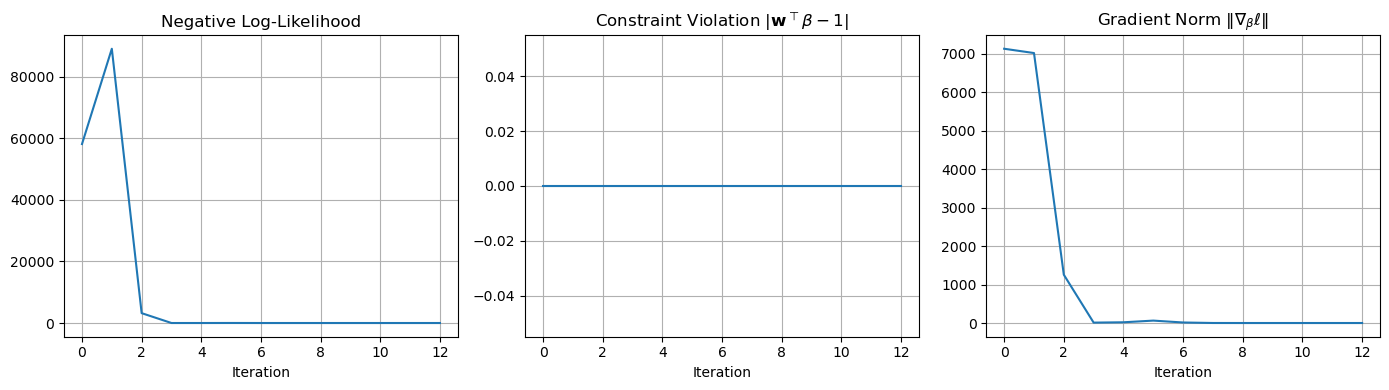

In [53]:
# Convergence diagnostics for the beta fit (separate fit)
beta_hist_df = pd.DataFrame(beta_history)
fig, axes = plt.subplots(1, 3, figsize=(14, 4))

axes[0].plot(beta_hist_df["loss"])
axes[0].set_title("Negative Log-Likelihood")
axes[0].set_xlabel("Iteration"); axes[0].grid()

axes[1].plot(beta_hist_df["constr_viol"])
axes[1].set_title("Constraint Violation $|\\mathbf{w}^\\top\\beta - 1|$")
axes[1].set_xlabel("Iteration"); axes[1].grid()

axes[2].plot(beta_hist_df["grad_norm"])
axes[2].set_title("Gradient Norm $\\|\\nabla_\\beta \\ell\\|$")
axes[2].set_xlabel("Iteration"); axes[2].grid()

plt.tight_layout(); plt.show()

### 5c. Option B — Joint Fit

Jointly minimize the NLL over $(\boldsymbol{\beta}, c)$ simultaneously:
$$\bigl(\hat{\boldsymbol{\beta}},\, \hat{c}\bigr) = \arg\min_{\boldsymbol{\beta}\ge 0}\; \ell(\boldsymbol{\beta},\, c)$$

In [55]:
res, history = fit_beta_c(
    D=D, A=A, v=_v_c, v_prime=_v_prime_c, c0=0,
    w_norm=None, xQ2=xQ2, Sigma=Sigma,
    nonneg_beta=True, pin_endpoints=True,
    return_history=True, opt_method="SLSQP", loss_scale=loss_scale
)

beta_hat_joint = res.beta_hat
c_hat_joint    = res.c_hat

# Choose the one-realization CI(s) for the joint MLE.
joint_mle_ci_method = "both"  # "bootstrap", "asymptotic", or "both"
joint_mle_hessian_method = "numerical"  # "analytical" or "numerical"
one_realization_joint_mle_ci_plot_methods = ("asymptotic",)
joint_mle_n_boot = 500
if joint_mle_ci_method not in {"bootstrap", "asymptotic", "both"}:
    raise ValueError(
        "joint_mle_ci_method must be 'bootstrap', 'asymptotic', or 'both'."
    )
if joint_mle_hessian_method not in {"analytical", "numerical"}:
    raise ValueError(
        "joint_mle_hessian_method must be 'analytical' or 'numerical'."
    )
available_joint_ci_methods = (
    {"bootstrap", "asymptotic"}
    if joint_mle_ci_method == "both" else {joint_mle_ci_method}
)
if (not one_realization_joint_mle_ci_plot_methods or
        not set(one_realization_joint_mle_ci_plot_methods) <= available_joint_ci_methods):
    raise ValueError(
        "one_realization_joint_mle_ci_plot_methods must be a nonempty subset "
        "of the joint-MLE CI methods being computed."
    )

ci_joint_bootstrap = None
se_joint_bootstrap = None
cb_joint = None
ci_joint_asymptotic = None
se_joint_asymptotic = None
joint_mle_ci_info = None

if joint_mle_ci_method in {"bootstrap", "both"}:
    lo, hi, cb_joint = bootstrap_confidence_interval(
        A=A, xQ2=xQ2, Sigma=Sigma, w_norm=None, c0=0,
        c_hat=c_hat_joint, beta_hat=beta_hat_joint,
        n_boot=joint_mle_n_boot, alpha=0.05, estimator="mle",
        loss_scale=loss_scale, klin=_klin, kquad=_kquad,
        nonneg_beta=True, pin_endpoints=True, opt="joint", verbose=True,
    )
    ci_joint_bootstrap = (lo, hi)
    se_joint_bootstrap = np.nanstd(cb_joint, ddof=1)
    print(f"Joint MLE bootstrap 95% CI = [{lo:.4f}, {hi:.4f}]")

if joint_mle_ci_method in {"asymptotic", "both"}:
    lo, hi, se_joint_asymptotic, joint_mle_ci_info = (
        joint_mle_asymptotic_confidence_interval(
            A=A, xQ2=xQ2, Sigma=Sigma, c_hat=c_hat_joint,
            beta_hat=beta_hat_joint, v=_v_c, v_prime=_v_prime_c,
            D=D, v_second=_v_second_c,
            w_norm=None, pin_endpoints=True, alpha=0.05,
            hessian_method=joint_mle_hessian_method,
        )
    )
    ci_joint_asymptotic = (lo, hi)
    print(
        f"Joint MLE asymptotic ({joint_mle_hessian_method} Hessian) "
        f"95% CI = [{lo:.4f}, {hi:.4f}]"
    )

# Backward-compatible scalar aliases prefer asymptotic when both are run.
if ci_joint_asymptotic is not None:
    ci_joint_lower, ci_joint_upper = ci_joint_asymptotic
    se_joint_mle = se_joint_asymptotic
    joint_mle_ci_label = "Asymptotic"
else:
    ci_joint_lower, ci_joint_upper = ci_joint_bootstrap
    se_joint_mle = se_joint_bootstrap
    joint_mle_ci_label = "Parametric bootstrap"

print(f"True c            = {c_true}")
print(f"Joint fit c       = {c_hat_joint:.4f}")
print(
    f"95% CI (joint, {joint_mle_ci_method}) = "
    f"[{ci_joint_lower:.4f}, {ci_joint_upper:.4f}]"
)

  Bootstrap replicate 50/500
  Bootstrap replicate 100/500
  Bootstrap replicate 150/500
  Bootstrap replicate 200/500
  Bootstrap replicate 250/500
  Bootstrap replicate 300/500
  Bootstrap replicate 350/500
  Bootstrap replicate 400/500
  Bootstrap replicate 450/500
  Bootstrap replicate 500/500
Joint MLE bootstrap 95% CI = [391.5838, 630.4287]
Joint MLE asymptotic (numerical Hessian) 95% CI = [392.4507, 629.5618]
True c            = 500
Joint fit c       = 511.0062
95% CI (joint, both) = [392.4507, 629.5618]


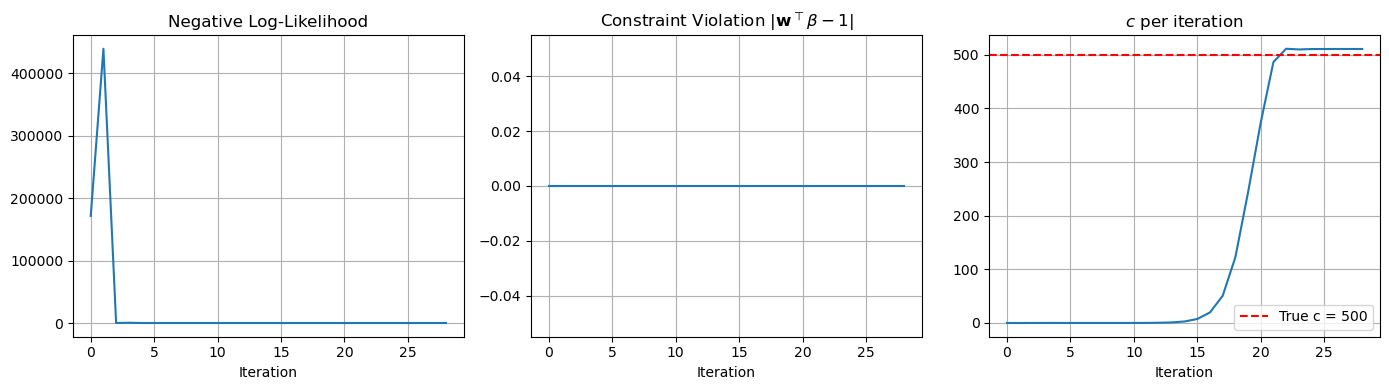

In [56]:
# Convergence diagnostics for the joint fit
history_df = pd.DataFrame(history)
fig, axes = plt.subplots(1, 3, figsize=(14, 4))

axes[0].plot(history_df["loss"])
axes[0].set_title("Negative Log-Likelihood")
axes[0].set_xlabel("Iteration"); axes[0].grid()

axes[1].plot(history_df["constr_viol"])
axes[1].set_title("Constraint Violation $|\mathbf{w}^\\top\\beta - 1|$")
axes[1].set_xlabel("Iteration"); axes[1].grid()

axes[2].plot(history_df["c"])
axes[2].axhline(c_true, color="red", linestyle="--", label=f"True c = {c_true}")
axes[2].set_title("$c$ per iteration")
axes[2].set_xlabel("Iteration"); axes[2].legend(); axes[2].grid()

plt.tight_layout(); plt.show()

In [57]:
print(f"{'':20s}  {'c_hat':>10s}  {'95% CI':>20s}")
print(f"{'True c':20s}  {c_true:>10.4f}  {'—':>20s}")
print(f"{'Separate fit':20s}  {c_hat_sep:>10.4f}  {f'[{ci_sep_lower:.4f}, {ci_sep_upper:.4f}]':>20s}")
print(f"{'Joint fit':20s}  {c_hat_joint:>10.4f}  {f'[{ci_joint_lower:.4f}, {ci_joint_upper:.4f}]':>20s}")

                           c_hat                95% CI
True c                  500.0000                     —
Separate fit            385.7818  [302.6828, 468.8808]
Joint fit               511.0062  [392.4507, 629.5618]


### 5d. One-step Estimator

The MLE $\hat c$ is biased due to the first-order bias from estimating the PDF function $f$.

The one-step estimator corrects this using the efficient influence function (EIF):
$$\hat c_{\rm one-step} = \hat c + \frac{\delta^\top \Sigma^{-1}(D - \hat\mu)}{\delta^\top \Sigma^{-1} \delta}$$
where $\delta = \partial_c \hat\mu - K h^*$ is the component of $\partial_c \hat\mu$ orthogonal to the nuisance tangent space $\{Kh : \mathbf{w}^\top h = 0\}$.

**Choose which estimate to compute one-step estimator.**  
Edit the cell below to select `"separate"` or `"joint"`.

In [58]:
fit_method = "separate"

if fit_method == "joint":
    beta_hat, c_hat = beta_hat_joint, c_hat_joint
else:
    beta_hat, c_hat = beta_hat_sep, c_hat_sep

In [59]:
# Compute the one-step estimate from both MLE starting points so that the
# Results plot can select separate and joint entries independently.
one_realization_results = {}
for method, beta_mle, c_mle in [
    ("separate", beta_hat_sep, c_hat_sep),
    ("joint", beta_hat_joint, c_hat_joint),
]:
    K_method = build_K_matrix(c_mle, A, xQ2=xQ2, klin=_klin, kquad=_kquad)
    K_prime_method = build_K_prime_matrix(
        c_mle, A, xQ2=xQ2, klin=_klin, kquad=_kquad
    )
    c_os_method, info_method = one_step_c(
        D, K_method, K_prime_method, beta_mle, c_mle, w_norm=None,
        Sigma=Sigma, pin_endpoints=True
    )
    ci_os_method = one_step_confidence_interval(info_method)
    one_realization_results[method] = {
        "beta": beta_mle, "plug_in": c_mle,
        "one_step": c_os_method, "one_step_info": info_method,
        "ci_one_step": ci_os_method[:2], "one_step_se": ci_os_method[2],
        "ci_mle": ((ci_sep_lower, ci_sep_upper) if method == "separate"
                   else (ci_joint_lower, ci_joint_upper)),
        "ci_mle_method": ("Parametric bootstrap" if method == "separate"
                          else joint_mle_ci_label),
        "mle_se": (np.nanstd(cb_sep, ddof=1) if method == "separate"
                   else se_joint_mle),
        "ci_mle_asymptotic": (None if method == "separate"
                              else ci_joint_asymptotic),
        "mle_se_asymptotic": (None if method == "separate"
                              else se_joint_asymptotic),
        "ci_mle_bootstrap": ((ci_sep_lower, ci_sep_upper)
                             if method == "separate" else ci_joint_bootstrap),
        "mle_se_bootstrap": (np.nanstd(cb_sep, ddof=1)
                             if method == "separate" else se_joint_bootstrap),
        "mle_ci_info": (None if method == "separate"
                        else joint_mle_ci_info),
        "boot_samples": (cb_sep if method == "separate" else cb_joint),
    }

# Preserve the original aliases for the fit selected above.
selected_result = one_realization_results[fit_method]
c_one_step = selected_result["one_step"]
one_step_info = selected_result["one_step_info"]
ci_os_lower, ci_os_upper = selected_result["ci_one_step"]
se_os = selected_result["one_step_se"]

print(f"True c                    = {c_true:.6g}")
print(f"MLE c ({fit_method}) = {c_hat:.6g} (error {c_hat - c_true:+.6g})")
print(f"One-step c                 = {c_one_step:.6g} (error {c_one_step - c_true:+.6g})")
print(f"EIF correction         = {one_step_info['eif']:.6g}")
print(f"95% CI      = [{ci_os_lower:.6g}, {ci_os_upper:.6g}]")

True c                    = 500
MLE c (separate) = 385.782 (error -114.218)
One-step c                 = 513.683 (error +13.683)
EIF correction         = 127.901
95% CI      = [405.699, 621.667]


In [60]:
K       = build_K_matrix(c_hat, A, xQ2=xQ2, klin=_klin, kquad=_kquad)
K_prime = build_K_prime_matrix(c_hat, A, xQ2=xQ2, klin=_klin, kquad=_kquad)

c_one_step, info = one_step_c(
    D, K, K_prime, beta_hat, c_hat, w_norm=None, Sigma=Sigma,
    pin_endpoints=True,
)

ci_os_lower, ci_os_upper, _ = one_step_confidence_interval(info)

print(f"True c          = {c_true}")
print(f"MLE ({fit_method:8s}) = {c_hat:.4f}  (error = {c_hat - c_true:+.4f})")
print(f"One-step        = {c_one_step:.4f}  (error = {c_one_step - c_true:+.4f})")
print(f"EIF correction  = {info['eif']:.4f}")
print(f"95% CI          = [{ci_os_lower:.4f}, {ci_os_upper:.4f}]")

True c          = 500
MLE (separate) = 385.7818  (error = -114.2182)
One-step        = 513.6830  (error = +13.6830)
EIF correction  = 127.9012
95% CI          = [405.6994, 621.6666]


In [61]:
# Select the entries to show in the one-realization Results plot.
# This uses the same (method, estimator) convention as the simulation plot.
one_realization_ci_plot = [
    ("separate", "plug_in"),
    ("separate", "one_step"),
    ("joint", "plug_in"),
]

valid_estimators = {"plug_in", "one_step"}
for method, estimator in one_realization_ci_plot:
    if method not in one_realization_results:
        raise ValueError(f"Unknown fit method {method!r}; use 'separate' or 'joint'.")
    if estimator not in valid_estimators:
        raise ValueError(
            f"Unknown estimator {estimator!r}; use 'plug_in' or 'one_step'."
        )

# Both MLE intervals were computed in their corresponding fit cells.
# Preserve scalar aliases for the selected fit method.
if one_realization_results[fit_method]["ci_mle"] is not None:
    ci_mle_lower, ci_mle_upper = one_realization_results[fit_method]["ci_mle"]
    bootstrap_samples = one_realization_results[fit_method]["boot_samples"]

---
## 6. Results

figure saved at: ../results/BCDMS/T3_fit_c=500_Lambda=500.pdf


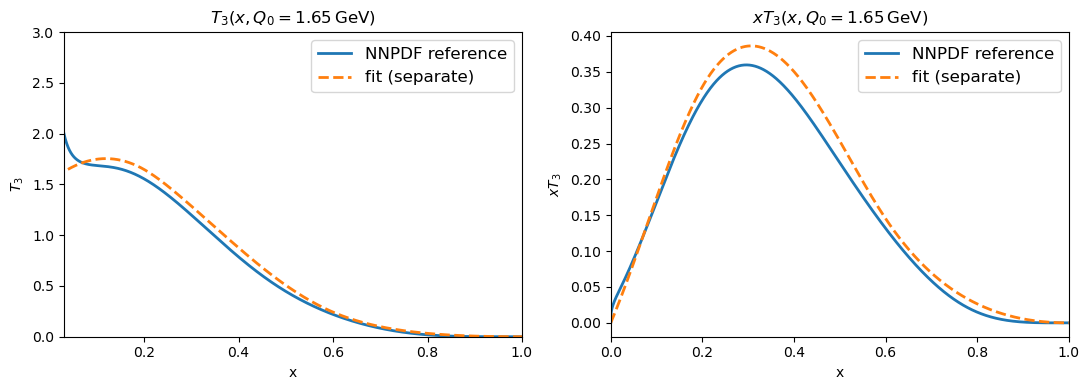

In [62]:
# PDF estimate vs truth
pt        = np.linspace(x_min, x_max, 1000)
basis_hat = sum(b * Bk(pt) for b, Bk in zip(beta_hat, B))
f_hat     = basis_hat if parametrize == "f" else basis_hat / pt

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))

ax1.plot(pt, f(pt),   lw=2, label="NNPDF reference")
ax1.plot(pt, f_hat,   lw=2, ls="--", label=fr"fit ({fit_method})")
ax1.set_xlim(0.03, 1); ax1.set_ylim(0, 3)
ax1.set_xlabel("x"); ax1.set_ylabel("$T_3$"); ax1.set_title(fr"$T_3(x,Q_0={Q0:g}\,\mathrm{{GeV}})$"); ax1.legend(fontsize=12)

ax2.plot(pt, pt * f(pt),   lw=2, label="NNPDF reference")
ax2.plot(pt, pt * f_hat,   lw=2, ls="--", label=fr"fit ({fit_method})")
ax2.set_xlim(0, 1)
ax2.set_xlabel("x"); ax2.set_ylabel(r"$xT_3$"); ax2.set_title(fr"$xT_3(x,Q_0={Q0:g}\,\mathrm{{GeV}})$"); ax2.legend(fontsize=12)

plt.tight_layout()
if save_fig:
    output = f"../results/BCDMS/T3_fit_c={c_true}_Lambda={Lambda}.pdf"
    fig.savefig(
        output,
        bbox_inches="tight",
    )
    print(f"figure saved at:", output)

plt.show()

Separate MLE chi2/N = 281.372/248 = 1.135
Joint MLE chi2/N = 267.089/248 = 1.077
figure saved at: ../results/BCDMS/data_fit_c=500_Lambda=500.pdf


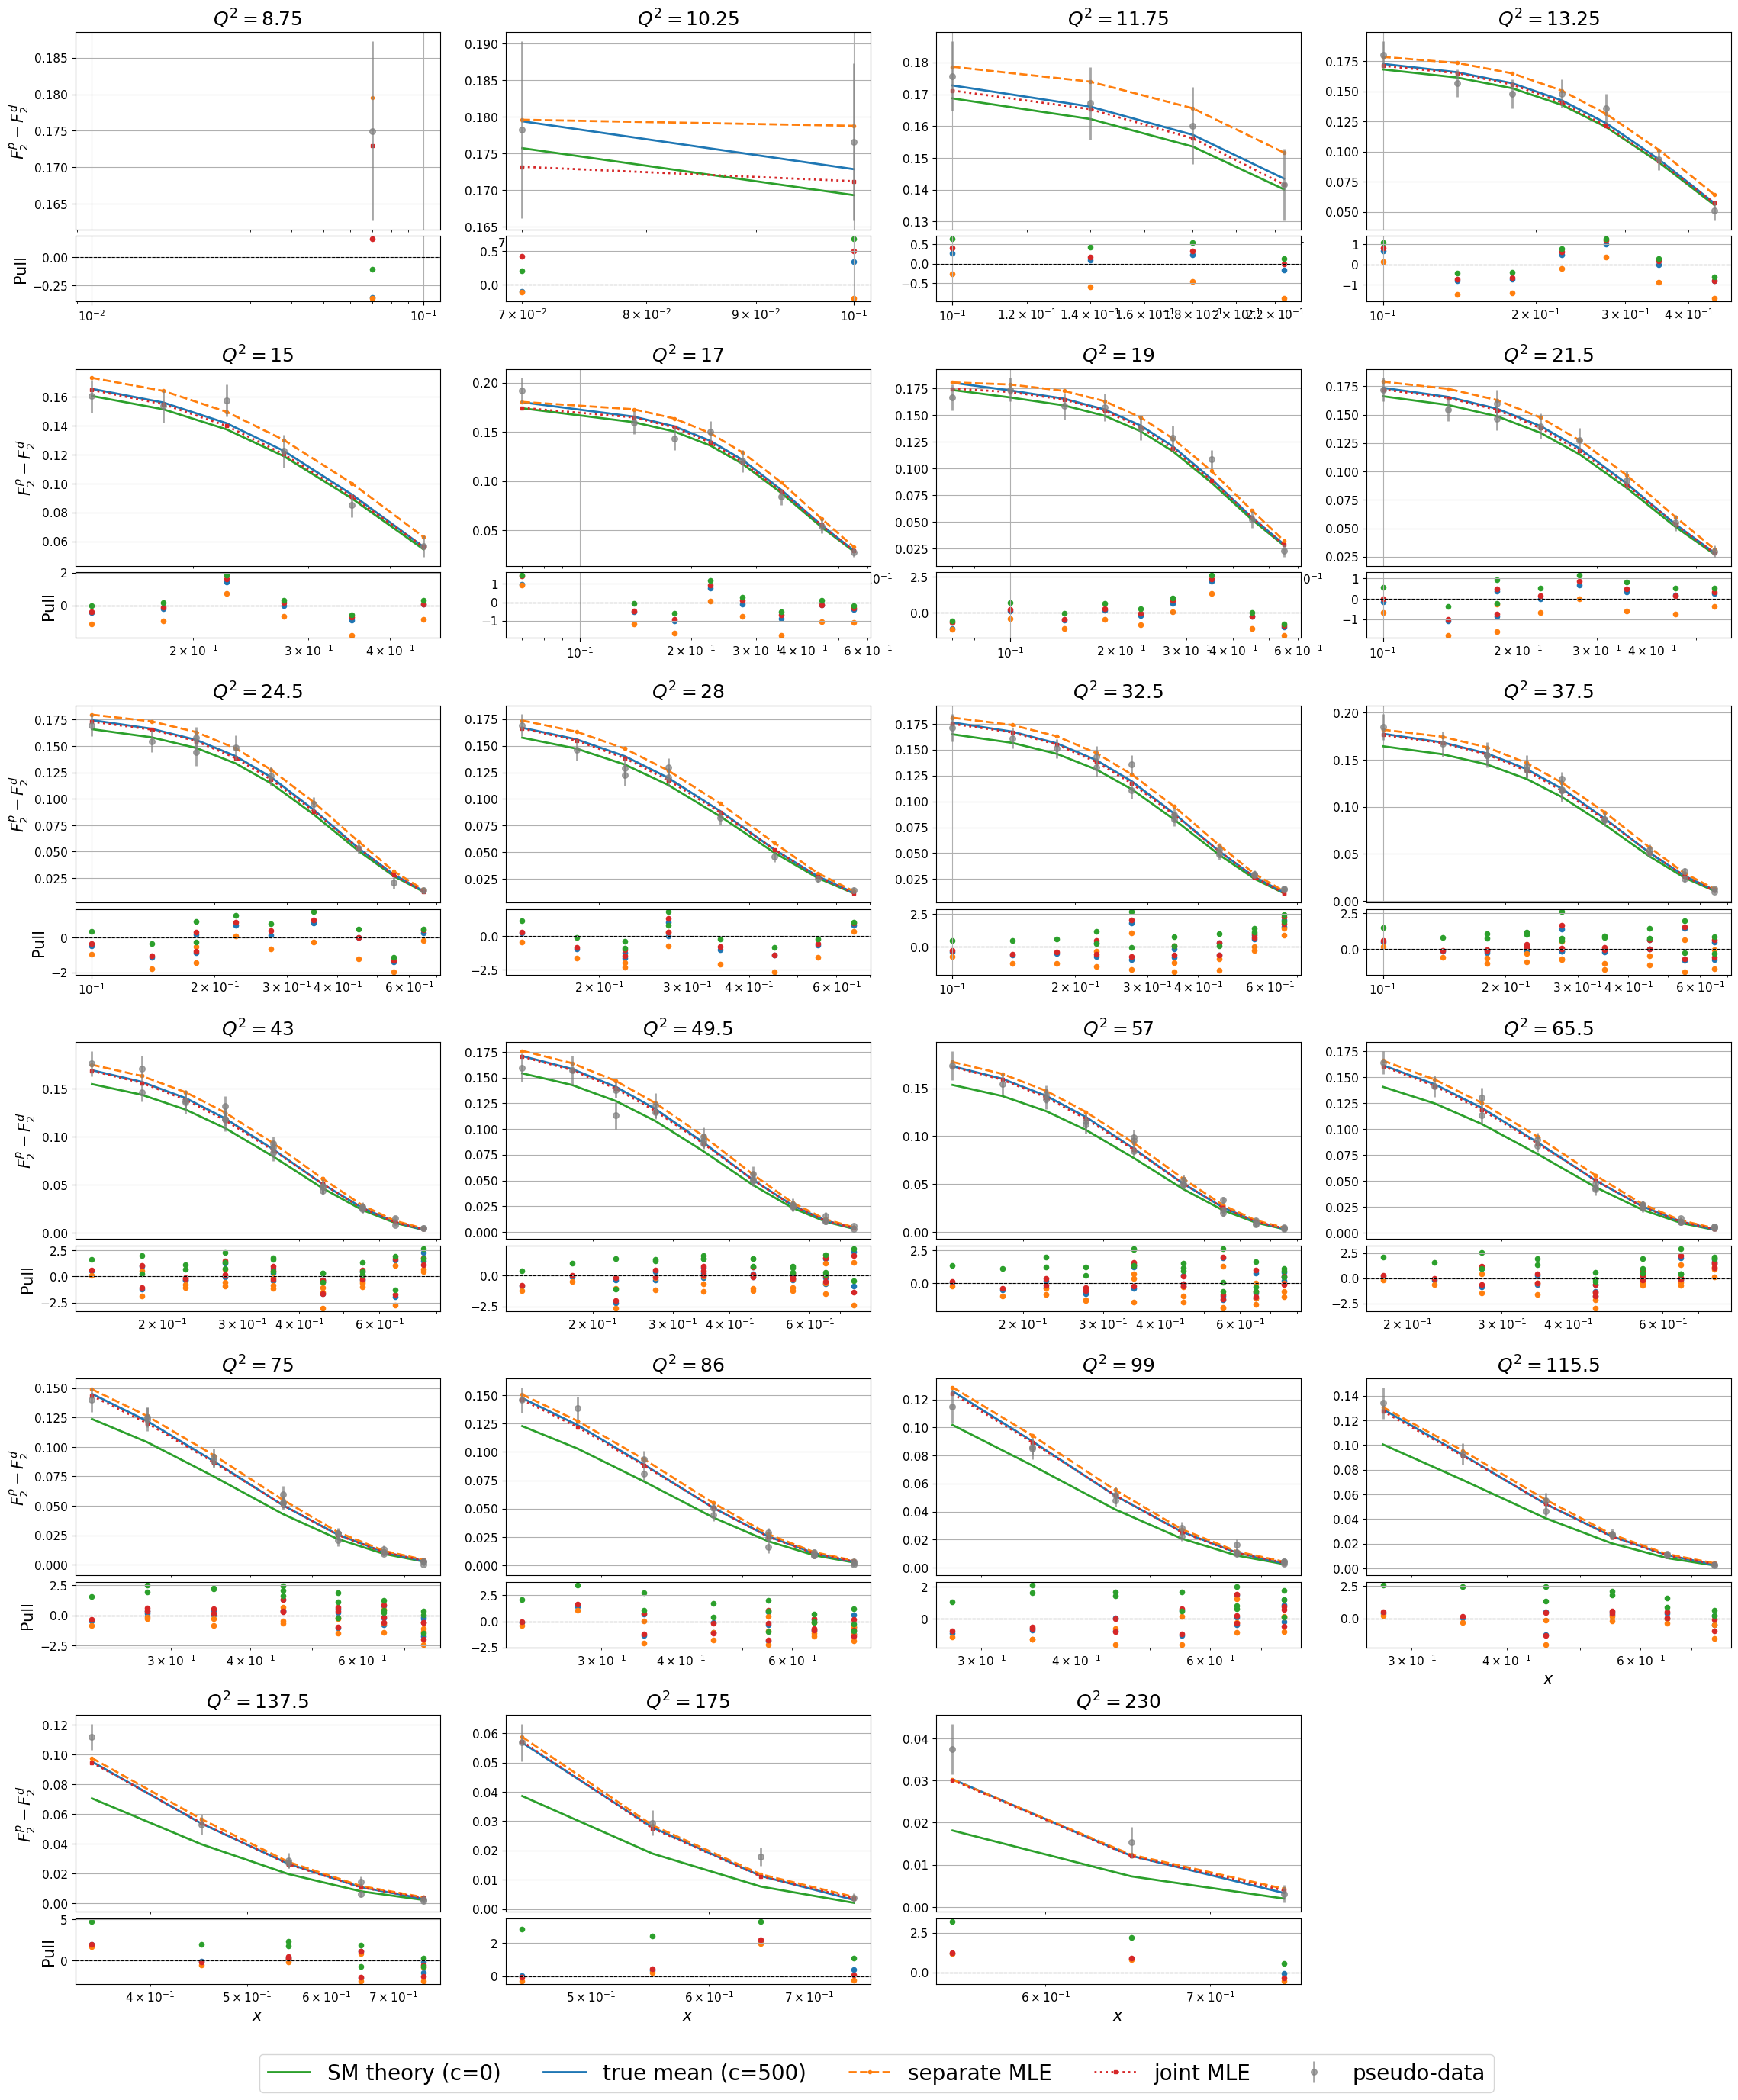

In [63]:
# Construct the data-level prediction for each MLE fitting strategy.
fit_predictions = {
    "Separate MLE": true_mean_basis(
        c_hat_sep, beta_hat_sep, A, xQ2=xQ2, klin=_klin, kquad=_kquad
    ),
    "Joint MLE": true_mean_basis(
        c_hat_joint, beta_hat_joint, A, xQ2=xQ2, klin=_klin, kquad=_kquad
    ),
}

# Preserve the selected-fit alias used elsewhere in the notebook.
mu_hat = fit_predictions[
    "Separate MLE" if method == "separate" else "Joint MLE"
]

# Report the data-level chi-square for both fits.
Sigma_factor = cho_factor(Sigma)
for fit_label, prediction in fit_predictions.items():
    residual = D - prediction
    chi2 = residual @ cho_solve(Sigma_factor, residual)
    print(
        f"{fit_label} chi2/N = {chi2:.3f}/{len(D)} = "
        f"{chi2 / len(D):.3f}"
    )

one_sigma_alpha = 2.0 * (1.0 - norm.cdf(1.0))
true_mean_label = f"true mean (c={c_true})"
fig = plot_by_Q2(
    {
        "SM theory (c=0)": T,
        true_mean_label: mu,
        "separate MLE": fit_predictions["Separate MLE"],
        "joint MLE": fit_predictions["Joint MLE"],
        "pseudo-data": D,
    },
    xQ2=xQ2, ncols=4, x_log_scale=True, alpha=one_sigma_alpha,
    y_label_first_column_only=True, legend_mode="figure",
    # q2_filter=lambda q2: (q2 > 75),
    series_styles={
        "SM theory (c=0)": dict(linestyle="-", linewidth=2, color="C2"),
        true_mean_label: dict(linestyle="-", linewidth=2, color="C0"),
        "separate MLE": dict(
            color="C1", linestyle="--", linewidth=2,
            marker="o", markersize=3,
        ),
        "joint MLE": dict(
            color="C3", linestyle=":", linewidth=2,
            marker="s", markersize=3,
        ),
        "pseudo-data": dict(
            kind="scatter", cov=Sigma, color="gray", s=30, alpha=0.7,
        ),
    },
    pull=[
        {"data": "pseudo-data", "ref": true_mean_label, "color": "C0"},
        {"data": "pseudo-data", "ref": "separate MLE", "color": "C1"},
        {"data": "pseudo-data", "ref": "joint MLE", "color": "C3"},
        {"data": "pseudo-data", "ref": "SM theory (c=0)", "color": "C2"},
    ],
    pull_legend=False,
    legend_fontsize=20,
    label_fontsize=15,
    title_fontsize=18,
    y_label=r"$F_2^p-F_2^d$",
)

# Enlarge each main/pull panel pair and tighten the gaps between pairs.
outer_grid = fig.axes[0].get_subplotspec().get_topmost_subplotspec().get_gridspec()
fig.set_size_inches(7 * outer_grid.ncols, 5.2 * outer_grid.nrows)
outer_grid.update(wspace=0.18, hspace=0.25)
fig.subplots_adjust(bottom=0.06)
# Enlarge tick labels on both the main and pull axes.
for ax in fig.axes:
    ax.tick_params(axis="both", which="both", labelsize=11)
    ax.xaxis.get_offset_text().set_fontsize(30)
    ax.yaxis.get_offset_text().set_fontsize(30)

if save_fig:
    output = f"../results/BCDMS/data_fit_c={c_true}_Lambda={Lambda}.pdf"
    fig.savefig(
        output,
        bbox_inches="tight",
    )
    print(f"figure saved at:", output)

,estimate,error,CI lower,CI upper,CI method
result,,,,,
Truth,500.000000,0.000000,NaN,NaN,None
Separate fit (bootstrap),385.781801,-114.218199,302.682795,468.880807,Parametric bootstrap
Joint fit (asymptotic),511.006213,11.006213,392.450656,629.561769,Asymptotic
Joint fit (bootstrap),511.006213,11.006213,391.583751,630.428674,Parametric bootstrap
One-step (separate),513.682975,13.682975,405.699382,621.666569,Asymptotic


Saved ../results/BCDMS/CI95_c=500_Lambda=500.pdf


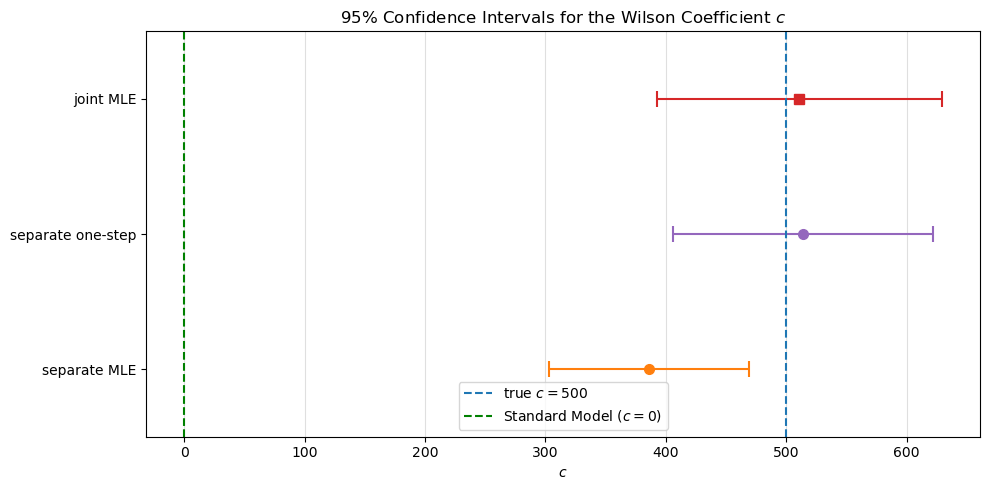

In [65]:
summary_rows = [{
    "result": "Truth", "estimate": c_true,
    "CI lower": np.nan, "CI upper": np.nan, "CI method": None,
}]
for method, row_label in [("separate", "Separate fit"), ("joint", "Joint fit")]:
    result = one_realization_results[method]
    for ci_method, ci, method_label in [
        ("asymptotic", result.get("ci_mle_asymptotic"),
         "Asymptotic"),
        ("bootstrap", result.get("ci_mle_bootstrap"),
         "Parametric bootstrap"),
    ]:
        if ci is None:
            continue
        summary_rows.append({
            "result": f"{row_label} ({ci_method})",
            "estimate": result["plug_in"],
            "CI lower": ci[0], "CI upper": ci[1],
            "CI method": method_label,
        })
summary_rows.append({
    "result": f"One-step ({fit_method})", "estimate": c_one_step,
    "CI lower": ci_os_lower, "CI upper": ci_os_upper,
    "CI method": "Asymptotic",
})
summary = pd.DataFrame(summary_rows).set_index("result")
summary.insert(1, "error", summary["estimate"] - c_true)
display(summary)

# Plot the selected one-realization confidence intervals.
estimator_colors = {"plug_in": "C1", "one_step": "C4"}
method_markers = {"separate": "o", "joint": "s"}
estimator_labels = {"plug_in": "MLE", "one_step": "one-step"}
ci_comparison = []
for method, estimator in one_realization_ci_plot:
    result = one_realization_results[method]
    if estimator == "plug_in":
        ci_entries = [
            ("asymptotic", result.get("ci_mle_asymptotic")),
            ("bootstrap", result.get("ci_mle_bootstrap")),
        ]
        ci_entries = [(name, ci) for name, ci in ci_entries if ci is not None]
        if method == "joint":
            ci_entries = [
                (name, ci) for name, ci in ci_entries
                if name in one_realization_joint_mle_ci_plot_methods
            ]
    else:
        ci_entries = [(None, result["ci_one_step"])]
    if not ci_entries:
        print(
            f"Skipping {method} {estimator_labels[estimator]}: "
            "no MLE CI is available."
        )
        continue
    for ci_method, ci in ci_entries:
        suffix = f" ({ci_method})" if ci_method is not None else ""
        ci_comparison.append({
            "label": f"{method} {estimator_labels[estimator]}",#{suffix}",
            "estimate": result[estimator], "lower": ci[0], "upper": ci[1],
            "color": "C3" if method == "joint" and estimator == "plug_in"
                else estimator_colors[estimator],
            "marker": method_markers[method],
        })

if not ci_comparison:
    raise ValueError("None of the selected entries has a confidence interval to plot.")

labels = [item["label"] for item in ci_comparison]
y = np.arange(len(ci_comparison))
fig, ax = plt.subplots(figsize=(10, 5))
for i, item in enumerate(ci_comparison):
    estimate = item["estimate"]
    ax.errorbar(
        estimate, y[i],
        xerr=[[estimate - item["lower"]], [item["upper"] - estimate]],
        fmt=item["marker"], capsize=6, capthick=1.5, linewidth=1.5,
        color=item["color"], markersize=7,
    )
ax.axvline(c_true, color="C0", linestyle="--", linewidth=1.5,
           label=fr"true $c = {c_true}$")
ax.axvline(0, color="green", linestyle="--", linewidth=1.5,
           label=r"Standard Model ($c = 0$)")
ax.set_yticks(y)
ax.set_yticklabels(labels)
ax.set_ylim(-0.5, len(labels) - 0.5)
ax.set_xlabel(r"$c$")
ax.set_title(r"95% Confidence Intervals for the Wilson Coefficient $c$")
ax.legend()
ax.grid(True, axis="x", alpha=0.4)
plt.tight_layout()
if save_fig:
    ci_plot_output = f"../results/BCDMS/CI95_c={c_true}_Lambda={Lambda}.pdf"
    fig.savefig(ci_plot_output, format="pdf", bbox_inches="tight")
    print(f"Saved {ci_plot_output}")
plt.show()

---
## 7. Simulation Study

We repeat the experiment $N_{\rm sim}$ times (each with a fresh draw of $\mathbf{D}$) to assess the
sampling distribution of the MLE and the one-step estimator.

`setup_experiment` pre-computes the basis and design matrix once; `run_single_experiment`
only generates new data and re-runs the optimization. Set `simulation_fit_method` to
`"separate"`, `"joint"`, or `"both"`. In `"both"` mode, both fits use the same
pseudo-data draw in each replicate for a paired comparison.

In [ ]:
# Simulation controls
run_simulation = True
N_sim = 1000
simulation_seed = 1 # use None for a fresh random sequence
simulation_fit_method = "both"  # "separate", "joint", or "both"
# Separate-MLE intervals remain bootstrap-based. The joint-MLE interval
# can use the nested bootstrap, the asymptotic interval, or both.
compute_bootstrap_coverage = True
simulation_joint_mle_ci_method = "asymptotic"  # "bootstrap", "asymptotic", or "both"
simulation_joint_mle_hessian_method = "numerical"  # "analytical" or "numerical"
n_boot_sim = 500
simulation_progress_every = 20

# Optimizers used by each simulation fitting strategy.
simulation_joint_optimizer = "SLSQP"
simulation_separate_beta_optimizer = "SLSQP"
simulation_separate_c_optimizer = "Nelder-Mead"
simulation_c_range = (-5.0, 5.0)  # used by grid_search
simulation_loss_scale = 1e2
if simulation_joint_mle_ci_method not in {"bootstrap", "asymptotic", "both"}:
    raise ValueError(
        "simulation_joint_mle_ci_method must be 'bootstrap', 'asymptotic', or 'both'."
    )
if simulation_joint_mle_hessian_method not in {"analytical", "numerical"}:
    raise ValueError(
        "simulation_joint_mle_hessian_method must be 'analytical' or 'numerical'."
    )
if (simulation_joint_mle_ci_method in {"bootstrap", "both"}
        and not compute_bootstrap_coverage):
    raise ValueError(
        "compute_bootstrap_coverage must be True when requesting bootstrap CIs."
    )

if simulation_fit_method == "both":
    simulation_fit_methods = ("separate", "joint")
elif simulation_fit_method in ("separate", "joint"):
    simulation_fit_methods = (simulation_fit_method,)
else:
    raise ValueError("simulation_fit_method must be 'separate', 'joint', or 'both'")

c_true = 500
#zero_coeff = lambda z, **kwargs: np.zeros_like(np.asarray(z, dtype=float))

setup_dict = setup_experiment(
    pdf=pdfset, c=c_true, f=f,
    xQ2=xQ2, grid=grid, W=W,
    degree=3, M=8,
    data_Sigma=Sigma,
    opt=simulation_fit_methods[0],
    parametrize=parametrize,
    c_opt=simulation_separate_c_optimizer,
    c_range=simulation_c_range, beta_opt=simulation_separate_beta_optimizer,
    c0=0, Lambda=Lambda,
    x_min=x_min, x_max=x_max,
    Q2_min=Q2_min, Q2_max=Q2_max,
    klin_fn=_klin, kquad_fn=_kquad,
    nonneg_beta=True, pin_endpoints=True,
    ncol_plots=2, x_log_scale=True,
    return_history=False, loss_scale=simulation_loss_scale,
    mle_constrained=False, one_step_constrained=False
)
setup_dicts = {}
for method in simulation_fit_methods:
    method_beta_optimizer = (
        simulation_joint_optimizer
        if method == "joint" else simulation_separate_beta_optimizer
    )
    setup_dicts[method] = {
        **setup_dict, "opt": method, "beta_opt": method_beta_optimizer,
        "c_opt": simulation_separate_c_optimizer,
        "c_range": simulation_c_range, "loss_scale": simulation_loss_scale,
    }

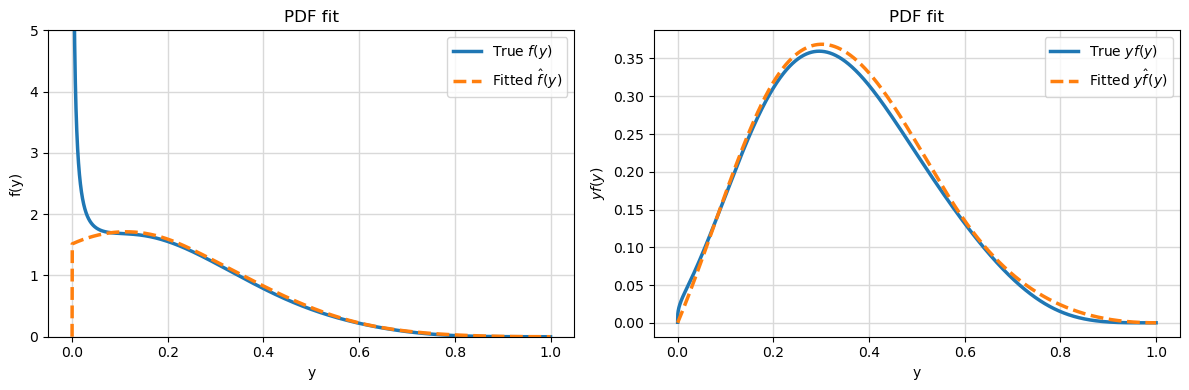

     Parameter       Value
0        c_hat  197.321813
1   c_one_step  266.485940
2       True c  250.000000
3       beta_0    0.000000
4       beta_1    0.100917
5       beta_2    0.396976
6       beta_3    0.370133
7       beta_4    0.107756
8       beta_5    0.010011
9       beta_6    0.000000
10      beta_7    0.000000
Normalization constraint (w^T beta_hat): 0.6971667014735051
Fitted pdf integrates to (xf parametrize): 0.6971667101955565


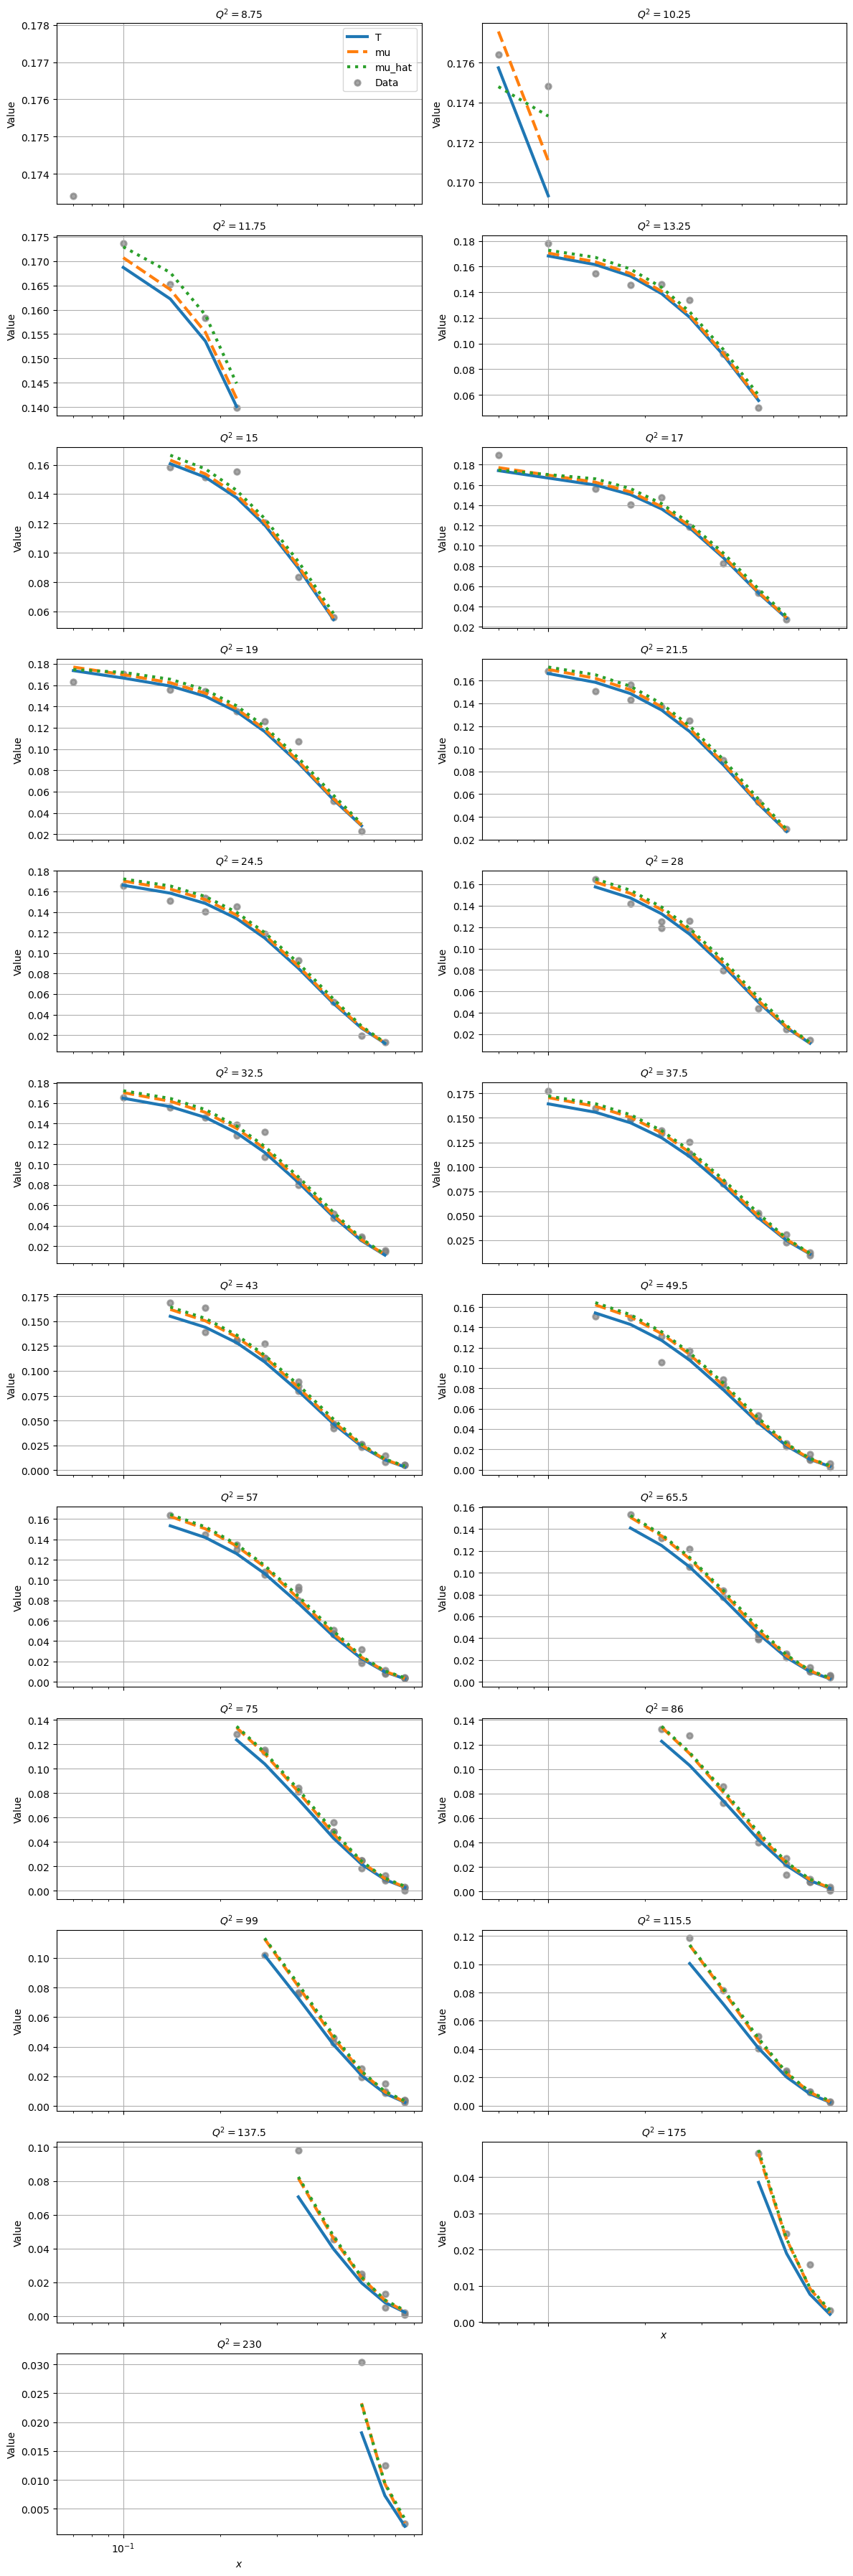

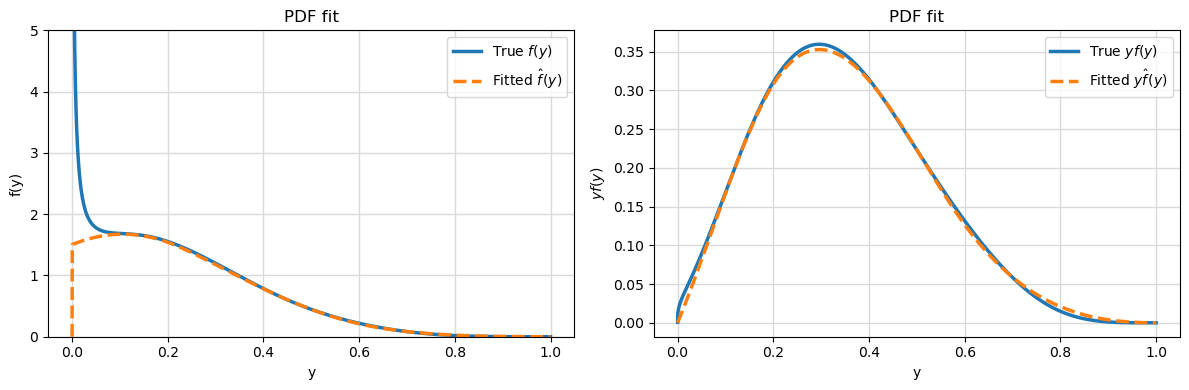

     Parameter       Value
0        c_hat  254.815706
1   c_one_step  269.350650
2       True c  250.000000
3       beta_0    0.000000
4       beta_1    0.100214
5       beta_2    0.386051
6       beta_3    0.347562
7       beta_4    0.101223
8       beta_5    0.006816
9       beta_6    0.000000
10      beta_7    0.000000
Normalization constraint (w^T beta_hat): 0.6721285988746898
Fitted pdf integrates to (xf parametrize): 0.6721286075359169


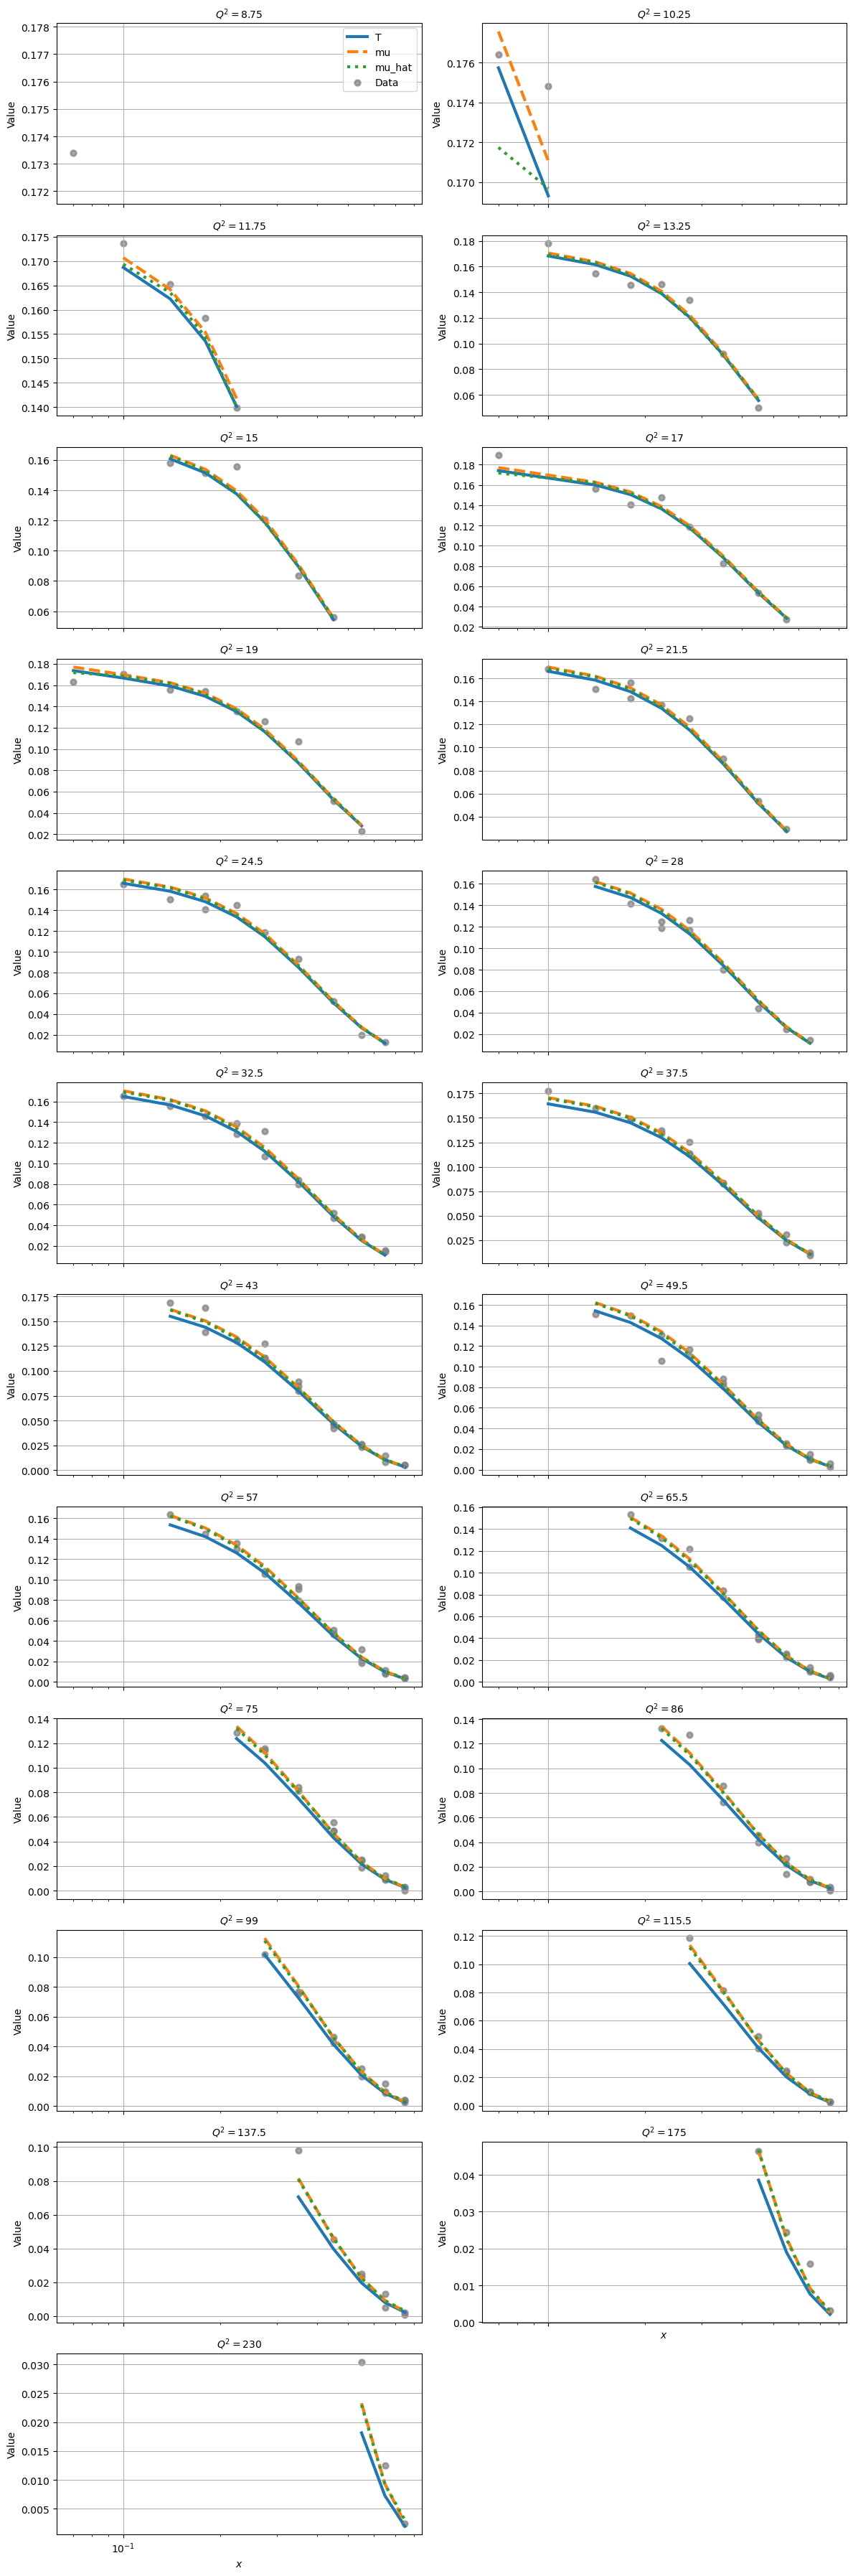

In [181]:
diagnostic_draw_seed = 0

for method in simulation_fit_methods:
    c_hat_diag, c_one_step_diag, info_diag = run_single_experiment(
        setup_dicts[method],
        diagnostics=True,
        rng=np.random.default_rng(diagnostic_draw_seed),
    )

In [182]:
A      = setup_dict['A']
w_norm = setup_dict['w_norm']
xQ2    = setup_dict['xQ2']
Sigma  = setup_dict['data_Sigma']

# Bootstrap must refit under the same constraint as the original MLE fit.
boot_w_norm = w_norm if setup_dict['mle_constrained'] else None

seed_sequence = np.random.SeedSequence(simulation_seed)
outer_seed, bootstrap_seed = seed_sequence.spawn(2)
simulation_rng = np.random.default_rng(outer_seed)
bootstrap_rng = np.random.default_rng(bootstrap_seed)

print("Simulation methods:", simulation_fit_methods)
print("MLE constrained:", setup_dict['mle_constrained'])
print("One-step constrained:", setup_dict['one_step_constrained'])
print("Nested bootstrap enabled:", compute_bootstrap_coverage)
print("Joint-MLE simulation CI:", simulation_joint_mle_ci_method)
print("Joint-MLE Hessian method:", simulation_joint_mle_hessian_method)

if run_simulation:
    simulation_results = {}
    for method in simulation_fit_methods:
        simulation_results[method] = {
            "plug_in": np.full(N_sim, np.nan),
            "one_step": np.full(N_sim, np.nan),
            "one_step_se": np.full(N_sim, np.nan),
            "ci_one_step": np.full((N_sim, 2), np.nan),
            "ci_mle_asymptotic": np.full((N_sim, 2), np.nan),
            "mle_se_asymptotic": np.full(N_sim, np.nan),
            "ci_mle_bootstrap": np.full((N_sim, 2), np.nan),
            "mle_se_bootstrap": np.full(N_sim, np.nan),
            "boot_samples": (
                np.full((N_sim, n_boot_sim), np.nan)
                if (compute_bootstrap_coverage
                    and (method == "separate" or
                         simulation_joint_mle_ci_method in {"bootstrap", "both"}))
                else None
            ),
        }

    for sim in range(N_sim):
        # Reinitialize each method with the same seed, hence the same data draw.
        data_draw_seed = int(simulation_rng.integers(0, np.iinfo(np.uint32).max))
        for method in simulation_fit_methods:
            result = simulation_results[method]
            try:
                c_hat_i, c_one_step_i, info_i = run_single_experiment(
                    setup_dicts[method], diagnostics=True, show_plots=False,
                    rng=np.random.default_rng(data_draw_seed),
                )
                result["plug_in"][sim] = c_hat_i
                result["one_step"][sim] = c_one_step_i

                lo, hi, se = one_step_confidence_interval(info_i['one_step'])
                result["ci_one_step"][sim] = (lo, hi)
                result["one_step_se"][sim] = se

                method_setup = setup_dicts[method]
                if (method == "joint" and
                        simulation_joint_mle_ci_method in {"asymptotic", "both"}):
                    lo_mle, hi_mle, se_mle, _ = (
                        joint_mle_asymptotic_confidence_interval(
                            A=A, xQ2=xQ2, Sigma=Sigma, c_hat=c_hat_i,
                            beta_hat=info_i["beta_hat"],
                            v=_v_c, v_prime=_v_prime_c,
                            D=info_i["D"], v_second=_v_second_c,
                            w_norm=boot_w_norm,
                            pin_endpoints=method_setup["pin_endpoints"],
                            alpha=0.05,
                            hessian_method=simulation_joint_mle_hessian_method,
                        )
                    )
                    result["ci_mle_asymptotic"][sim] = (lo_mle, hi_mle)
                    result["mle_se_asymptotic"][sim] = se_mle
                if (compute_bootstrap_coverage and
                        (method == "separate" or
                         simulation_joint_mle_ci_method in {"bootstrap", "both"})):
                    bootstrap_draw_seed = int(
                        bootstrap_rng.integers(0, np.iinfo(np.uint32).max)
                    )
                    lo_b, hi_b, samples_b = bootstrap_confidence_interval(
                        A=A, w_norm=boot_w_norm, xQ2=xQ2, Sigma=Sigma,
                        c0=method_setup['c0'],
                        c_hat=c_hat_i, beta_hat=info_i['beta_hat'],
                        n_boot=n_boot_sim, alpha=0.05, estimator="mle",
                        opt=method, c_opt=method_setup['c_opt'],
                        c_range=method_setup['c_range'],
                        beta_opt=method_setup['beta_opt'],
                        loss_scale=method_setup['loss_scale'],
                        klin=method_setup['klin'], kquad=method_setup['kquad'],
                        nonneg_beta=method_setup['nonneg_beta'],
                        pin_endpoints=method_setup['pin_endpoints'],
                        seed=bootstrap_draw_seed, verbose=False,
                    )
                    result["ci_mle_bootstrap"][sim] = (lo_b, hi_b)
                    result["mle_se_bootstrap"][sim] = np.nanstd(samples_b, ddof=1)
                    result["boot_samples"][sim] = samples_b
            except (RuntimeError, ValueError, np.linalg.LinAlgError) as error:
                print(f"{method} replicate {sim} failed: {error}")

        if simulation_progress_every and (sim + 1) % simulation_progress_every == 0:
            print(f"  {sim + 1}/{N_sim} done")

    print("\n--- Results ---")
    for method, result in simulation_results.items():
        result["valid_plugin"] = np.isfinite(result["plug_in"])
        result["valid_os"] = np.isfinite(result["one_step"])
        result["covered_one_step"] = (
            (result["ci_one_step"][:, 0] <= c_true)
            & (result["ci_one_step"][:, 1] >= c_true)
        )
        for ci_method in ("asymptotic", "bootstrap"):
            cis = result[f"ci_mle_{ci_method}"]
            ses = result[f"mle_se_{ci_method}"]
            result[f"covered_mle_{ci_method}"] = (
                (cis[:, 0] <= c_true) & (cis[:, 1] >= c_true)
            )
            result[f"valid_mle_ci_{ci_method}"] = (
                np.isfinite(result["plug_in"]) & np.isfinite(ses)
                & np.all(np.isfinite(cis), axis=1)
            )

        print(f"\n[{method}]")
        for label, key, valid_key in [
            ("MLE", "plug_in", "valid_plugin"),
            ("One-step", "one_step", "valid_os"),
        ]:
            values = result[key][result[valid_key]]
            print(
                f"{label:10s} valid={len(values):4d}/{N_sim} "
                f"mean={values.mean():.4f} median={np.median(values):.4f} "
                f"bias={values.mean() - c_true:+.4f} "
                f"std={values.std(ddof=1):.4f}"
            )
        valid_os = result["valid_os"]
        print(
            f"One-step 95% CI coverage: "
            f"{result['covered_one_step'][valid_os].mean():.3f}"
        )

        for ci_method in ("asymptotic", "bootstrap"):
            valid_mle_ci = result[f"valid_mle_ci_{ci_method}"]
            if np.any(valid_mle_ci):
                coverage = result[f"covered_mle_{ci_method}"][valid_mle_ci].mean()
                print(f"MLE {ci_method} 95% CI coverage: {coverage:.3f}")
else:
    print("Set run_simulation=True to run the repeated experiments.")

Simulation methods: ('separate', 'joint')
MLE constrained: False
One-step constrained: False
Nested bootstrap enabled: True
Joint-MLE simulation CI: asymptotic
Joint-MLE Hessian method: numerical
  20/1000 done
  40/1000 done
  60/1000 done
  80/1000 done
  100/1000 done
  120/1000 done
  140/1000 done
  160/1000 done
  180/1000 done
  200/1000 done
  220/1000 done
  240/1000 done
  260/1000 done
  280/1000 done
  300/1000 done
  320/1000 done
  340/1000 done
  360/1000 done
  380/1000 done
  400/1000 done
  420/1000 done
  440/1000 done
  460/1000 done
  480/1000 done
  500/1000 done
  520/1000 done
  540/1000 done
  560/1000 done
  580/1000 done
  600/1000 done
  620/1000 done
  640/1000 done
  660/1000 done
  680/1000 done
  700/1000 done
  720/1000 done
  740/1000 done
  760/1000 done
  780/1000 done
  800/1000 done
  820/1000 done
  840/1000 done
  860/1000 done
  880/1000 done
  900/1000 done
  920/1000 done
  940/1000 done
  960/1000 done
  980/1000 done
  1000/1000 done

--- Re

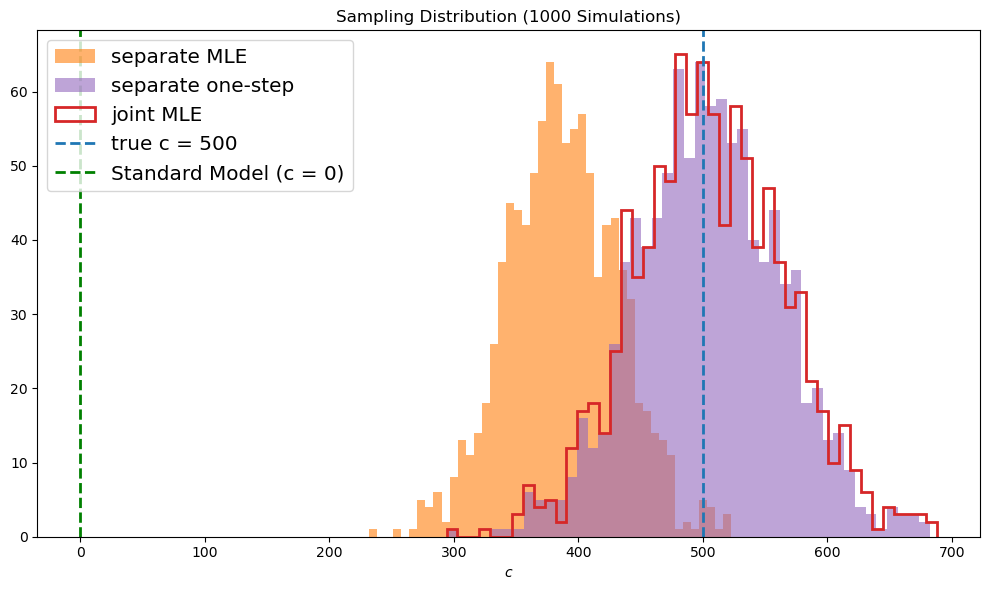

figure save at: ../results/BCDMS/sampling_dist_c=500_Lambda=500.pdf


In [69]:
# Select any fitted (method, estimator) pairs for all plots below.
# Example: [("separate", "plug_in"), ("joint", "one_step")]
sampling_distribution_plot = [
    ("separate", "plug_in"),
    ("separate", "one_step"),
    ("joint", "plug_in"),
]
estimator_colors = {"plug_in": "C1", "one_step": "C4"}
method_hist_styles = {
    "separate": dict(histtype="bar", alpha=0.6),
    "joint": dict(histtype="step", linewidth=2),
}
estimator_labels = {"plug_in": "MLE", "one_step": "one-step"}

for method, estimator in sampling_distribution_plot:
    if method not in simulation_results:
        raise ValueError(
            f"Cannot plot {method!r}: it was not run. "
            f"Available methods are {tuple(simulation_results)}."
        )
    if estimator not in estimator_labels:
        raise ValueError(
            f"Unknown estimator {estimator!r}; use 'plug_in' or 'one_step'."
        )

fig, ax = plt.subplots(figsize=(10, 6))
for method, estimator in sampling_distribution_plot:
    result = simulation_results[method]
    valid_key = "valid_plugin" if estimator == "plug_in" else "valid_os"
    ax.hist(
        result[estimator][result[valid_key]], bins=45,
        color="C3" if method == "joint" and estimator == "plug_in"
            else estimator_colors[estimator],
        label=f"{method} {estimator_labels[estimator]}",
        **method_hist_styles[method],
    )
ax.axvline(c_true, color="C0", linestyle="--", linewidth=2, label=f"true c = {c_true}")
ax.axvline(0, color="green", linestyle="--", linewidth=2, label=f"Standard Model (c = 0)")
ax.set_xlabel("$c$")
ax.set_title(f"Sampling Distribution ({N_sim} Simulations)")
ax.legend(fontsize='x-large')
plt.tight_layout(); plt.show()
if save_fig:
    output = f"../results/BCDMS/sampling_dist_c={c_true}_Lambda={int(Lambda)}.pdf"
    fig.savefig(output, bbox_inches="tight")
    print("figure save at:", output)


---
## 8. Uncertainty Quantification

The diagnostics below follow `sampling_distribution_plot`. MLE coverage uses bootstrap intervals and is skipped when `compute_bootstrap_coverage=False`.

1. **CI strip plot** — each CI uses the estimator color; solid lines/circles cover $c_{\rm true}$, while dotted lines/crosses miss.
2. **Coverage comparison** — bar chart of empirical coverage rates for the MLE bootstrap CI and the one-step analytical CI, both at the nominal level.
3. **CI width distribution** — boxplot of CI widths across replicates for each method.
4. **Coverage curve** — empirical coverage at each nominal level.


In [70]:
# Plotting-only choice: change this after running or loading the simulation.
simulation_joint_mle_ci_plot_methods = ("asymptotic",)
available_simulation_joint_ci_methods = (
    {"bootstrap", "asymptotic"}
    if simulation_joint_mle_ci_method == "both"
    else {simulation_joint_mle_ci_method}
)
if (not simulation_joint_mle_ci_plot_methods or
        not set(simulation_joint_mle_ci_plot_methods)
        <= available_simulation_joint_ci_methods):
    raise ValueError(
        "simulation_joint_mle_ci_plot_methods must be a nonempty subset "
        "of the joint-MLE CI methods that were computed."
    )

# Build the coverage series from the same selection as the histogram.
coverage_plot_series = []
for method, estimator in sampling_distribution_plot:
    result = simulation_results[method]
    if estimator == "one_step":
        estimates = result["one_step"]
        ses = result["one_step_se"]
        cis = result["ci_one_step"]
        label = f"{method} one-step"
    else:  # plug_in
        added_mle_series = False
        ci_methods_to_plot = (
            simulation_joint_mle_ci_plot_methods
            if method == "joint" else ("bootstrap",)
        )
        for ci_method in ci_methods_to_plot:
            cis = result[f"ci_mle_{ci_method}"]
            ses = result[f"mle_se_{ci_method}"]
            valid = (
                np.isfinite(result["plug_in"]) & np.isfinite(ses)
                & np.all(np.isfinite(cis), axis=1)
            )
            if not np.any(valid):
                continue
            coverage_plot_series.append({
                "method": method, "estimator": estimator,
                "ci_method": ci_method,
                "label": f"{method} MLE", #({ci_method})",
                "estimates": result["plug_in"], "ses": ses,
                "cis": cis, "valid": valid,
            })
            added_mle_series = True
        if not added_mle_series:
            print(f"Skipping {method} MLE: no confidence intervals computed.")
        continue

    valid = (
        np.isfinite(estimates)
        & np.isfinite(ses)
        & np.all(np.isfinite(cis), axis=1)
    )
    coverage_plot_series.append({
        "method": method, "estimator": estimator,
        "ci_method": "one_step", "label": label,
        "estimates": estimates, "ses": ses, "cis": cis, "valid": valid,
    })

if not coverage_plot_series:
    raise ValueError(
        "No selected estimator has confidence intervals available for coverage plots."
    )


In [ ]:
# ── CI strip plots ───────────────────────────────────────────────────
for series in coverage_plot_series:
    valid = series["valid"]
    cis = series["cis"]
    estimates = series["estimates"]
    indices = np.flatnonzero(valid)
    covered = (cis[:, 0] <= c_true) & (cis[:, 1] >= c_true)
    series_color = estimator_colors[series["estimator"]]

    fig, ax = plt.subplots(figsize=(8, max(5, len(indices) // 8)))
    for row, i in enumerate(indices):
        linestyle = '-' if covered[i] else ':'
        marker = 'o' if covered[i] else 'x'
        alpha_i = 0.8 if covered[i] else 0.45
        ax.plot(cis[i], [row, row], color=series_color, ls=linestyle, lw=1.0, alpha=alpha_i)
        ax.plot(estimates[i], row, marker, color=series_color, ms=2.5, alpha=alpha_i)

    coverage_rate = covered[valid].mean()
    ax.axvline(c_true, color='black', lw=2, ls='--', zorder=5)
    ax.legend(handles=[
        Line2D([0], [0], color=series_color, lw=2, ls='-', label='Covered'),
        Line2D([0], [0], color=series_color, lw=2, ls=':', label='Missed'),
        Line2D([0], [0], color='black', lw=2, ls='--', label=f'True $c = {c_true}$'),
    ], fontsize=12)
    ax.set_xlabel('$c$', fontsize=13)
    ax.set_ylabel('Valid simulation index')
    ax.set_title(
        f"{series['label'].capitalize()} 95% CIs — coverage {coverage_rate*100:.1f}%",
        fontsize=13,
    )
    plt.tight_layout(); plt.show()

/var/folders/qm/350m2x392jj9m78jcv5zmhx80000gn/T/ipykernel_98538/124387842.py:34: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot(


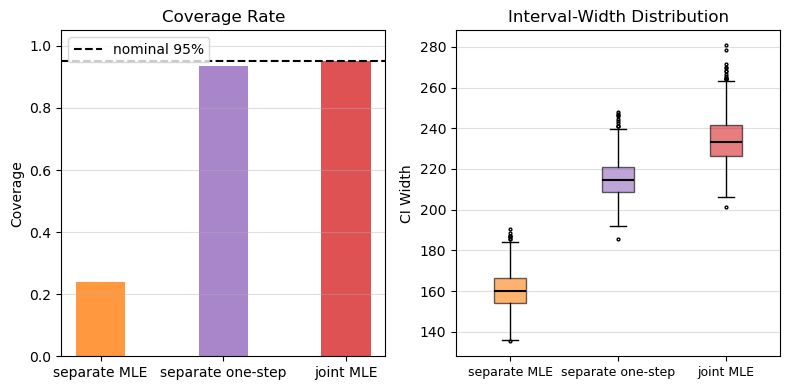

Figure saved at: ../results/BCDMS/coverage_width_c=500_Lambda=500.pdf


In [75]:
estimator_colors = {"plug_in": "C1", "one_step": "C4"}
method_hatches = {"separate": "", "joint": ""}
labels = [series["label"] for series in coverage_plot_series]
CI_arrays = [series["cis"][series["valid"]] for series in coverage_plot_series]
colors = [
    "C3" if series["method"] == "joint" and series["estimator"] == "plug_in"
    else estimator_colors[series["estimator"]]
    for series in coverage_plot_series
]
hatches = [method_hatches[series["method"]] for series in coverage_plot_series]

alpha     = 0.05
coverages = [((CI[:, 0] <= c_true) & (CI[:, 1] >= c_true)).mean() for CI in CI_arrays]
widths    = [CI[:, 1] - CI[:, 0] for CI in CI_arrays]
se_cov    = [np.sqrt(cov * (1 - cov) / N_sim) for cov in coverages]

fig, axes = plt.subplots(1, 2, figsize=(8, 4))

ax = axes[0]
x = np.arange(len(labels))
for i, (cov, se, color, hatch) in enumerate(zip(coverages, se_cov, colors, hatches)):
    ax.bar(x[i], cov, capsize=5, color=color, hatch=hatch, alpha=0.8, width=0.4)#, yerr=se)
ax.axhline(1 - alpha, color="black", linestyle="--", linewidth=1.5,
           label=f"nominal {int((1-alpha)*100)}%")
ax.set_xticks(x)
ax.set_xticklabels(labels)
ax.set_ylabel("Coverage")
ax.set_title("Coverage Rate")
ax.set_ylim(0, 1.05)
ax.legend()
ax.grid(True, axis="y", alpha=0.4)

ax = axes[1]
bp = ax.boxplot(
    widths, labels=labels, patch_artist=True,
    medianprops=dict(color="black", linewidth=1.5),
    whiskerprops=dict(color="black"),
    capprops=dict(color="black"),
    flierprops=dict(marker='.', markersize=4, markeredgecolor="black"),
)
for patch, color, hatch in zip(bp['boxes'], colors, hatches):
    patch.set_facecolor(color)
    patch.set_hatch(hatch)
    patch.set_alpha(0.6)
ax.tick_params(axis="x", labelsize=9)
ax.set_ylabel("CI Width")
ax.set_title("Interval-Width Distribution")
ax.grid(True, axis="y", alpha=0.4)

plt.tight_layout()
plt.show()

if save_fig:
    output = f"../results/BCDMS/coverage_width_c={c_true}_Lambda={int(Lambda)}.pdf"
    fig.savefig(output, bbox_inches="tight")
    print("Figure saved at:", output)


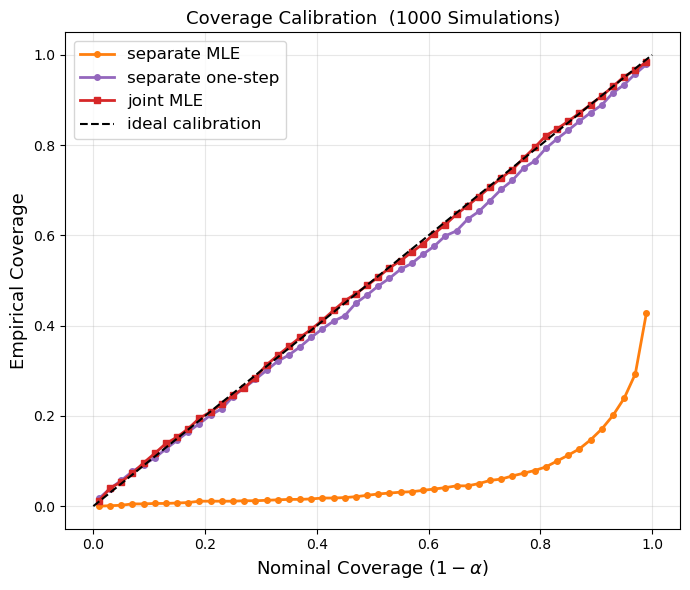

Figure saved at: ../results/BCDMS/coverage_calibration_c=500_Lambda=500.pdf


In [74]:
alphas = np.linspace(0.01, 0.99, 50)
nom_levels = 1 - alphas
estimator_colors = {"plug_in": "C1", "one_step": "C4"}
method_markers = {"separate": "o", "joint": "s"}
fig, ax = plt.subplots(figsize=(7, 6))

for series in coverage_plot_series:
    valid = series["valid"]
    estimates = series["estimates"][valid]
    ses = series["ses"][valid]
    empirical = []
    for a in alphas:
        z = norm.ppf(1 - a / 2)
        lo = estimates - z * ses
        hi = estimates + z * ses
        empirical.append(np.mean((lo <= c_true) & (hi >= c_true)))
    ax.plot(
        nom_levels, empirical,
        color=(
            "C3" if series["method"] == "joint" and series["estimator"] == "plug_in"
            else estimator_colors[series["estimator"]]
        ),
        marker=method_markers[series["method"]],
        lw=2, ms=4, label=series["label"],
    )
ax.plot([0.0, 1], [0.0, 1], 'k--', lw=1.5, label='ideal calibration')
ax.set_xlabel('Nominal Coverage $(1 - \\alpha)$', fontsize=13)
ax.set_ylabel('Empirical Coverage', fontsize=13)
ax.set_title(f'Coverage Calibration  ({N_sim} Simulations)', fontsize=13)
ax.legend(fontsize=12)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

if save_fig:
    output = f"../results/BCDMS/coverage_calibration_c={c_true}_Lambda={int(Lambda)}.pdf"
    fig.savefig(output, bbox_inches="tight")
    print("Figure saved at:", output)


In [184]:
# Save simulation results for later analysis.
simulation_output = (
    f"simulation_results/BCDMS/V3_simulation_results_c={c_true}_Lambda={Lambda}.npz"
)
if run_simulation:
    from pathlib import Path
    Path(simulation_output).parent.mkdir(parents=True, exist_ok=True)
    save_payload = dict(
        notebook_file="T3_demo.ipynb", data_archive="Dataset/data_208.npz",
        numpy_version=np.__version__, pdfset=pdfset,
        c_true=c_true, N_sim=N_sim, Lambda=Lambda,
        simulation_seed=(-1 if simulation_seed is None else simulation_seed),
        simulation_fit_method=simulation_fit_method,
        simulation_fit_methods=np.asarray(simulation_fit_methods),
        simulation_joint_mle_ci_method=simulation_joint_mle_ci_method,
        simulation_joint_mle_hessian_method=simulation_joint_mle_hessian_method,
        compute_bootstrap_coverage=compute_bootstrap_coverage,
        n_boot_sim=n_boot_sim, bootstrap_ci_alpha=0.05,
        spline_degree=setup_dict["degree"], n_basis=setup_dict["M"],
        parametrize=setup_dict["parametrize"], c0=setup_dict["c0"],
        joint_optimizer=simulation_joint_optimizer,
        separate_beta_optimizer=simulation_separate_beta_optimizer,
        separate_c_optimizer=simulation_separate_c_optimizer,
        c_range=np.asarray(simulation_c_range), loss_scale=simulation_loss_scale,
        nonnegative_beta=setup_dict["nonneg_beta"],
        pin_endpoints=setup_dict["pin_endpoints"],
        mle_constrained=setup_dict["mle_constrained"],
        one_step_constrained=setup_dict["one_step_constrained"],
        x_min=setup_dict["x_min"], x_max=setup_dict["x_max"],
        Q2_min=setup_dict["Q2_min"], Q2_max=setup_dict["Q2_max"],
        sampling_distribution_plot=np.asarray(sampling_distribution_plot),
        xQ2=xQ2, Sigma=Sigma, grid=grid, FK_matrix=W, design_matrix=A,
        generating_mean=setup_dict["mu"], w_norm=w_norm,
        klin_values=setup_dict["klin"](xQ2[:, 1]),
        kquad_values=setup_dict["kquad"](xQ2[:, 1]),
    )
    for method, result in simulation_results.items():
        save_payload[f"{method}_plug_in_estimates"] = result["plug_in"]
        save_payload[f"{method}_one_step_estimates"] = result["one_step"]
        save_payload[f"{method}_CIs_one_step"] = result["ci_one_step"]
        save_payload[f"{method}_one_step_SEs"] = result["one_step_se"]
        save_payload[f"{method}_CIs_mle_asymptotic"] = result["ci_mle_asymptotic"]
        save_payload[f"{method}_mle_asymptotic_SEs"] = result["mle_se_asymptotic"]
        save_payload[f"{method}_CIs_mle_bootstrap"] = result["ci_mle_bootstrap"]
        save_payload[f"{method}_mle_bootstrap_SEs"] = result["mle_se_bootstrap"]
        if result["boot_samples"] is not None:
            save_payload[f"{method}_all_boot_samples"] = result["boot_samples"]
    np.savez(simulation_output, **save_payload)
    print(f"Saved {simulation_output}")

Saved simulation_results/BCDMS/V3_simulation_results_c=250_Lambda=500.npz


In [66]:
simulation_output = (
    f"simulation_results/BCDMS/T3_simulation_results_c=500_Lambda=500.npz"
)

# Read back saved results and restore the state used by plotting cells.
with np.load(simulation_output) as saved:
    c_true = saved["c_true"].item()
    N_sim = saved["N_sim"].item()
    Lambda = saved["Lambda"].item()
    simulation_fit_method = saved["simulation_fit_method"].item()
    simulation_fit_methods = tuple(saved["simulation_fit_methods"].tolist())
    simulation_joint_mle_ci_method = (
        saved["simulation_joint_mle_ci_method"].item()
        if "simulation_joint_mle_ci_method" in saved.files else "bootstrap"
    )
    simulation_joint_mle_hessian_method = (
        saved["simulation_joint_mle_hessian_method"].item()
        if "simulation_joint_mle_hessian_method" in saved.files
        else "analytical"
    )
    compute_bootstrap_coverage = bool(saved["compute_bootstrap_coverage"].item())
    n_boot_sim = saved["n_boot_sim"].item()
    simulation_seed_saved = (
        saved["simulation_seed"].item() if "simulation_seed" in saved.files else -1
    )
    simulation_seed = None if simulation_seed_saved == -1 else int(simulation_seed_saved)
    sampling_distribution_plot = (
        [tuple(row) for row in saved["sampling_distribution_plot"].tolist()]
        if "sampling_distribution_plot" in saved.files
        else [(method, estimator) for method in simulation_fit_methods
              for estimator in ("plug_in", "one_step")]
    )

    # Keep all non-result entries in one self-describing configuration dictionary.
    result_suffixes = (
        "plug_in_estimates", "one_step_estimates", "CIs_one_step",
        "one_step_SEs", "CIs_mle", "mle_SEs",
        "CIs_mle_asymptotic", "mle_asymptotic_SEs",
        "CIs_mle_bootstrap", "mle_bootstrap_SEs", "all_boot_samples",
    )
    result_keys = {
        f"{method}_{suffix}"
        for method in simulation_fit_methods for suffix in result_suffixes
    }
    simulation_config = {}
    for key in saved.files:
        if key in result_keys:
            continue
        value = saved[key]
        simulation_config[key] = value.item() if value.ndim == 0 else value.copy()

    simulation_results = {}
    for method in simulation_fit_methods:
        result = {
            "plug_in": saved[f"{method}_plug_in_estimates"].copy(),
            "one_step": saved[f"{method}_one_step_estimates"].copy(),
            "ci_one_step": saved[f"{method}_CIs_one_step"].copy(),
            "one_step_se": saved[f"{method}_one_step_SEs"].copy(),
            "ci_mle_asymptotic": np.full((N_sim, 2), np.nan),
            "mle_se_asymptotic": np.full(N_sim, np.nan),
            "ci_mle_bootstrap": np.full((N_sim, 2), np.nan),
            "mle_se_bootstrap": np.full(N_sim, np.nan),
        }
        for ci_method in ("asymptotic", "bootstrap"):
            ci_key = f"{method}_CIs_mle_{ci_method}"
            se_key = f"{method}_mle_{ci_method}_SEs"
            if ci_key in saved.files:
                result[f"ci_mle_{ci_method}"] = saved[ci_key].copy()
            if se_key in saved.files:
                result[f"mle_se_{ci_method}"] = saved[se_key].copy()

        # Backward compatibility with files containing only one MLE CI array.
        legacy_ci_key = f"{method}_CIs_mle"
        legacy_se_key = f"{method}_mle_SEs"
        if legacy_ci_key in saved.files:
            legacy_method = ("asymptotic" if method == "joint" and
                             simulation_joint_mle_ci_method == "asymptotic"
                             else "bootstrap")
            result[f"ci_mle_{legacy_method}"] = saved[legacy_ci_key].copy()
            if legacy_se_key in saved.files:
                result[f"mle_se_{legacy_method}"] = saved[legacy_se_key].copy()
        boot_key = f"{method}_all_boot_samples"
        result["boot_samples"] = (
            saved[boot_key].copy() if boot_key in saved.files else None
        )
        if (result["boot_samples"] is not None and
                not np.any(np.isfinite(result["mle_se_bootstrap"]))):
            result["mle_se_bootstrap"] = np.nanstd(
                result["boot_samples"], axis=1, ddof=1
            )
        result["valid_plugin"] = np.isfinite(result["plug_in"])
        result["valid_os"] = np.isfinite(result["one_step"])
        result["covered_one_step"] = (
            (result["ci_one_step"][:, 0] <= c_true)
            & (result["ci_one_step"][:, 1] >= c_true)
        )
        for ci_method in ("asymptotic", "bootstrap"):
            cis = result[f"ci_mle_{ci_method}"]
            ses = result[f"mle_se_{ci_method}"]
            result[f"covered_mle_{ci_method}"] = (
                (cis[:, 0] <= c_true) & (cis[:, 1] >= c_true)
            )
            result[f"valid_mle_ci_{ci_method}"] = (
                np.isfinite(result["plug_in"]) & np.isfinite(ses)
                & np.all(np.isfinite(cis), axis=1)
            )
        if result["boot_samples"] is not None:
            result["valid_boot"] = np.all(
                np.isfinite(result["ci_mle_bootstrap"]), axis=1
            )
        simulation_results[method] = result

run_simulation = True
print(f"Loaded {N_sim} simulations for {simulation_fit_methods}.")
print("\nSaved simulation configuration:")
for key in sorted(simulation_config):
    value = simulation_config[key]
    if isinstance(value, np.ndarray):
        print(f"  {key}: array shape={value.shape}, dtype={value.dtype}")
    else:
        print(f"  {key}: {value!r}")

Loaded 1000 simulations for ('separate', 'joint').

Saved simulation configuration:
  FK_matrix: array shape=(248, 50), dtype=float64
  Lambda: 500
  N_sim: 1000
  Q2_max: 230.0
  Q2_min: 8.75
  Sigma: array shape=(248, 248), dtype=float64
  bootstrap_ci_alpha: 0.05
  c0: 0
  c_range: array shape=(2,), dtype=float64
  c_true: 500
  compute_bootstrap_coverage: True
  data_archive: 'Dataset/data_208.npz'
  design_matrix: array shape=(248, 8), dtype=float64
  generating_mean: array shape=(248,), dtype=float64
  grid: array shape=(50,), dtype=float64
  joint_optimizer: 'SLSQP'
  klin_values: array shape=(248,), dtype=float64
  kquad_values: array shape=(248,), dtype=float64
  loss_scale: 100.0
  mle_constrained: False
  n_basis: 8
  n_boot_sim: 500
  nonnegative_beta: True
  notebook_file: 'T3_demo.ipynb'
  numpy_version: '2.2.6'
  one_step_constrained: False
  parametrize: 'xf'
  pdfset: 'NNPDF40_nnlo_as_01180'
  pin_endpoints: True
  sampling_distribution_plot: array shape=(3, 2), dtype=